In [1]:
# ============================================================
# CELL 1 — EMOBERTA-BASE + AGGRESSIVE
# FROZEN TRANSFORMER EXPERIMENT
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_NAME = (
    "tae898/emoberta-base"
)

EXPERIMENT_NAME = (
    "EmoBERTa-base + Aggressive"
)

CLEANING_METHOD = (
    "Aggressive"
)

MAX_LENGTH = 512

METADATA_DIM = 53

FREEZE_TRANSFORMER = True


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "emoberta_aggressive"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)


os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# FIXED EXPERIMENTAL CONTROLS
# ============================================================

FIXED_CONTROLS = {

    "user_level_split":
        True,

    "train_users":
        6135,

    "validation_users":
        767,

    "test_users":
        767,

    "diagnostic_anchor_removal":
        True,

    "metadata_features":
        53,

    "metadata_scaling":
        "TRAIN ONLY",

    "training_balance":
        "2013 negative + 2013 positive",

    "batch_size":
        16,

    "context_length":
        512,

    "random_seed":
        42,

    "checkpoint_metric":
        "Validation F1",

    "early_stopping_patience":
        2,

    "maximum_epochs":
        10,

    "transformer_frozen":
        True
}


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE")
print("=" * 60)

print()

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print()

print(
    "Model:",
    MODEL_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)

print(
    "Seed:",
    SEED
)


# ============================================================
# AGGRESSIVE CLEANING POLICY
# ============================================================

print()
print("=" * 60)
print("AGGRESSIVE CLEANING POLICY")
print("=" * 60)

print("01. Remove URLs")
print("02. Remove malformed URL variants")
print("03. Remove user mentions")
print("04. Remove hashtag symbols")
print("05. Remove HTML entities / markup")
print("06. Remove punctuation")
print("07. Remove emojis")
print("08. Remove emoticons")
print("09. Remove special symbols")
print("10. Normalize whitespace")
print("11. Lowercase text")


# ============================================================
# MODEL INFORMATION
# ============================================================

print()
print("=" * 60)
print("EMOBERTA-BASE CONFIGURATION")
print("=" * 60)

print(
    "Base encoder:",
    "RoBERTa-base"
)

print(
    "Pretrained emotion model:",
    MODEL_NAME
)

print(
    "Backbone training:",
    "FROZEN"
)

print(
    "Downstream classifier:",
    "TRAINABLE"
)

print(
    "Metadata branch:",
    "TRAINABLE"
)


# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_dimension":
        METADATA_DIM,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "seed":
        SEED,

    "fixed_controls":
        FIXED_CONTROLS,

    "aggressive_cleaning_policy": [

        "remove standard URLs",

        "remove malformed URL variants",

        "remove user mentions",

        "remove hashtag symbols",

        "remove HTML entities / markup",

        "remove punctuation",

        "remove emojis",

        "remove emoticons",

        "remove special symbols",

        "normalize whitespace",

        "lowercase text"
    ]
}


with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(
    "✓ EmoBERTa-base selected"
)

print(
    "✓ Aggressive cleaning selected"
)

print(
    "✓ Context length = 512"
)

print(
    "✓ Metadata dimension = 53"
)

print(
    "✓ Transformer backbone = FROZEN"
)

print(
    "✓ Downstream layers = TRAINABLE"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ Aggressive cleaning policy defined"
)

print(
    "✓ Result directory created"
)

print(
    "✓ Checkpoint directory created"
)

print(
    "✓ Backup directory created"
)

print(
    "✓ Experiment configuration saved"
)

print(
    "✓ MentalBERT outputs untouched"
)

print(
    "✓ EmoBERTa RAW outputs untouched"
)

print(
    "✓ Selective outputs untouched"
)

print(
    "✓ Emotion-Based outputs untouched"
)

print(
    "✓ Fixed experiment controls recorded"
)

EMOBERTA-BASE + AGGRESSIVE

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: tae898/emoberta-base
Cleaning: Aggressive
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

AGGRESSIVE CLEANING POLICY
01. Remove URLs
02. Remove malformed URL variants
03. Remove user mentions
04. Remove hashtag symbols
05. Remove HTML entities / markup
06. Remove punctuation
07. Remove emojis
08. Remove emoticons
09. Remove special symbols
10. Normalize whitespace
11. Lowercase text

EMOBERTA-BASE CONFIGURATION
Base encoder: RoBERTa-base
Pretrained emotion model: tae898/emoberta-base
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE

CELL 1 COMPLETE
✓ EmoBERTa-base selected
✓ Aggressive cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Aggressive cleaning policy defined
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory cre

In [2]:
# ============================================================
# CELL 2 — EMOBERTA-BASE + AGGRESSIVE
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ============================================================
# SPLIT PATHS
# ============================================================

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ============================================================
# FILE CHECK
# ============================================================

assert os.path.exists(
    TRAIN_PATH
), f"TRAIN split not found: {TRAIN_PATH}"

assert os.path.exists(
    VAL_PATH
), f"VALIDATION split not found: {VAL_PATH}"

assert os.path.exists(
    TEST_PATH
), f"TEST split not found: {TEST_PATH}"

print()
print("✓ All split files found")


# ============================================================
# LOAD DATA
# ============================================================

print()
print("Loading TRAIN...")

train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")

val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")

test_df = pd.read_pickle(
    TEST_PATH
)


# ============================================================
# SPLIT SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert train_df.shape == (
    6135,
    82
)

assert val_df.shape == (
    767,
    82
)

assert test_df.shape == (
    767,
    82
)


# ============================================================
# REQUIRED COLUMNS
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)


print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)


# No duplicates
assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


# ============================================================
# CROSS-SPLIT OVERLAP
# ============================================================

train_val_overlap = (
    train_users
    &
    val_users
)

train_test_overlap = (
    train_users
    &
    test_users
)

val_test_overlap = (
    val_users
    &
    test_users
)


print(
    "TRAIN ↔ VAL:",
    len(train_val_overlap)
)

print(
    "TRAIN ↔ TEST:",
    len(train_test_overlap)
)

print(
    "VAL ↔ TEST:",
    len(val_test_overlap)
)


assert len(
    train_val_overlap
) == 0

assert len(
    train_test_overlap
) == 0

assert len(
    val_test_overlap
) == 0


print()
print(
    "✓ No duplicate users"
)

print(
    "✓ No cross-split overlap"
)


# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")

print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")

print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")

print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# EXACT LABEL CHECK
# ============================================================

assert (
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 515,
        1: 252
    }
)

assert (
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 516,
        1: 251
    }
)


# ============================================================
# TIMELINE TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

for df, split_name in [

    (
        train_df,
        "TRAIN"
    ),

    (
        val_df,
        "VALIDATION"
    ),

    (
        test_df,
        "TEST"
    )

]:

    null_count = int(
        df[
            "timeline_text"
        ]
        .isna()
        .sum()
    )

    print(
        f"{split_name} null timeline texts:",
        null_count
    )

    assert null_count == 0


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print(
    "✓ Exact user-level split restored"
)

print(
    "✓ TRAIN = 6135"
)

print(
    "✓ VALIDATION = 767"
)

print(
    "✓ TEST = 767"
)

print(
    "✓ Same labels as previous experiments"
)

print(
    "✓ No duplicate users"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Timeline text available"
)

EMOBERTA-BASE + AGGRESSIVE — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATIO

In [3]:
# ============================================================
# CELL 3 — EMOBERTA-BASE + AGGRESSIVE
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict


print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE DIRECTORY
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), (
    f"D1 timeline directory not found: "
    f"{D1_TIMELINE_DIR}"
)


# ============================================================
# FIND D1 TIMELINE FILES
# ============================================================

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(
    d1_timeline_files
) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]


compiled_anchor_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]


compiled_exclusion_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


# ============================================================
# EXACT ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(
        text
    ).strip()

    if not text:
        return False

    # Exclusions first
    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    # Anchor patterns
    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)


assert len(train_positive_users) == 2013
assert len(val_positive_users) == 252
assert len(test_positive_users) == 251
assert len(all_positive_users) == 2516


# ============================================================
# INDEX TIMELINE FILES
# ============================================================

timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN POSITIVE D1 TIMELINES
# ============================================================

anchor_records = []

users_processed = set()
tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# CONTROL ASSERTIONS
# ============================================================

assert len(users_processed) == 2516
assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847

assert len(train_anchor_pairs) == 1476
assert len(val_anchor_pairs) == 190
assert len(test_anchor_pairs) == 181


# ============================================================
# SAVE
# ============================================================

emoberta_aggressive_anchor_df = pd.DataFrame(
    anchor_records
)

emoberta_aggressive_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print(
    "✓ Exact anchor detector reproduced"
)

print(
    "✓ 1,847 unique anchors confirmed"
)

print(
    "✓ 1,920 anchor records confirmed"
)

print(
    "✓ TRAIN = 1,476 unique anchors"
)

print(
    "✓ VAL = 190 unique anchors"
)

print(
    "✓ TEST = 181 unique anchors"
)

print(
    "✓ No D2 users included"
)

print(
    "✓ Anchor records saved"
)

print(
    "✓ No timelines modified yet"
)

EMOBERTA-BASE + AGGRESSIVE — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — EMOBERTA-BASE + AGGRESSIVE
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ============================================================
# EXPECTED COUNTS
# ============================================================

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920


# ============================================================
# PRE-REMOVAL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records)
    - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ============================================================
# SPLIT-LEVEL ANCHOR RECORD COUNTS
# ============================================================

train_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in test_positive_users
]


print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(
    anchor_pairs
)


# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(username):

    kept_texts = []
    removed_count = 0

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if tweet_text:

                    kept_texts.append(
                        tweet_text
                    )

    return (
        " ".join(kept_texts),
        removed_count
    )


# ============================================================
# COPY ORIGINAL DATAFRAMES
# ============================================================

train_emoberta_aggressive_df = (
    train_df.copy(
        deep=True
    )
)

val_emoberta_aggressive_df = (
    val_df.copy(
        deep=True
    )
)

test_emoberta_aggressive_df = (
    test_df.copy(
        deep=True
    )
)


# ============================================================
# BUILD POSITIVE USER TEXT
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(
    all_positive_users
):

    (
        anchor_removed_text,
        removed_count
    ) = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = anchor_removed_text

    if username in train_positive_users:

        train_removed += removed_count

    elif username in val_positive_users:

        val_removed += removed_count

    elif username in test_positive_users:

        test_removed += removed_count


# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    ==
    EXPECTED_TOTAL_REMOVED
)

print(
    "✓ Record-level removal exactly matches "
    "previous experiments"
)


# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [

    train_emoberta_aggressive_df,
    val_emoberta_aggressive_df,
    test_emoberta_aggressive_df

]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )

    # D2 users remain unchanged

    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_emoberta_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_aggressive_df,
        "TEST"
    )

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index(
            "username"
        )
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index(
            "username"
        )
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {split_name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_emoberta_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_aggressive_df,
        "TEST"
    )

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: users and labels unchanged"
    )


# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_emoberta_aggressive_df
    ),

    (
        "VALIDATION",
        val_emoberta_aggressive_df
    ),

    (
        "TEST",
        test_emoberta_aggressive_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_emoberta_aggressive_df
    .head(3)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row[
            "anchor_removed_text"
        ][:1200]
    )


# ============================================================
# SAVE
# ============================================================

train_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ No aggressive cleaning applied yet")
print("✓ Anchor-removed source saved")

EMOBERTA-BASE + AGGRESSIVE — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_

In [5]:
# ============================================================
# CELL 5 — EMOBERTA-BASE + AGGRESSIVE
# TEXT CLEANING
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — TEXT CLEANING")
print("=" * 60)


# ============================================================
# AGGRESSIVE CLEANING FUNCTION
# ============================================================

def aggressive_clean_text(text):

    if text is None:
        return ""

    text = str(text)

    # --------------------------------------------------------
    # 1. Remove standard URLs
    # --------------------------------------------------------

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 2. Remove malformed URL variants
    #    Example: https:/example.com
    # --------------------------------------------------------

    text = re.sub(
        r"https?:/\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 3. Remove user mentions
    # --------------------------------------------------------

    text = re.sub(
        r"(?<![A-Za-z0-9_])@[A-Za-z0-9_]+",
        " ",
        text
    )

    # --------------------------------------------------------
    # 4. Remove hashtag symbol + hashtag text
    # --------------------------------------------------------

    text = re.sub(
        r"#[A-Za-z0-9_]+",
        " ",
        text
    )

    # --------------------------------------------------------
    # 5. Decode HTML entities
    # --------------------------------------------------------

    text = html.unescape(
        text
    )

    # --------------------------------------------------------
    # 6. Remove remaining HTML-like tags
    # --------------------------------------------------------

    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # --------------------------------------------------------
    # 7. Remove punctuation / special symbols
    # --------------------------------------------------------

    text = re.sub(
        r"[^A-Za-z0-9\s]",
        " ",
        text
    )

    # --------------------------------------------------------
    # 8. Lowercase
    # --------------------------------------------------------

    text = text.lower()

    # --------------------------------------------------------
    # 9. Normalize whitespace
    # --------------------------------------------------------

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ============================================================
# SANITY TESTS
# ============================================================

print()
print("=" * 60)
print("AGGRESSIVE CLEANING TEST")
print("=" * 60)


test_examples = [

    (
        "I CAN'T sleep 😭!!! https://t.co/example @someone #depression",
        "i can t sleep"
    ),

    (
        "RT @user: I am feeling REALLY bad today!!!",
        "rt i am feeling really bad today"
    ),

    (
        "Everything is okay... or maybe NOT 😔",
        "everything is okay or maybe not"
    ),

    (
        "I have been feeling hopeless for weeks :(",
        "i have been feeling hopeless for weeks"
    ),

    (
        "I am 23 years old and this happened 3 times!!!",
        "i am 23 years old and this happened 3 times"
    ),

    (
        "Feeling sooo tired... but I'm trying :) #mentalhealth",
        "feeling sooo tired but i m trying"
    ),

    (
        "hello @user123!!!",
        "hello"
    ),

    (
        "#depression #mentalhealth",
        ""
    ),

    (
        "visit https://example.com now",
        "visit now"
    ),

    (
        "visit https:/example.com now",
        "visit now"
    )
]


for number, (
    raw_text,
    expected_contains
) in enumerate(
    test_examples,
    start=1
):

    cleaned_text = aggressive_clean_text(
        raw_text
    )

    print()
    print(
        f"EXAMPLE {number}"
    )

    print(
        "RAW:"
    )

    print(
        raw_text
    )

    print(
        "AGGRESSIVELY CLEANED:"
    )

    print(
        cleaned_text
    )


# ============================================================
# APPLY CLEANING
# ============================================================

print()
print("=" * 60)
print("APPLYING AGGRESSIVE CLEANING")
print("=" * 60)


for df, split_name in [

    (
        train_emoberta_aggressive_df,
        "TRAIN"
    ),

    (
        val_emoberta_aggressive_df,
        "VALIDATION"
    ),

    (
        test_emoberta_aggressive_df,
        "TEST"
    )

]:

    df["model_text"] = (
        df[
            "anchor_removed_text"
        ]
        .fillna("")
        .astype(str)
        .map(
            aggressive_clean_text
        )
    )

    empty_count = int(
        (
            df[
                "model_text"
            ]
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty after cleaning: "
        f"{empty_count}"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_emoberta_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_aggressive_df,
        "TEST"
    )

]:

    assert (
        original_df[
            "user_id"
        ].tolist()
        ==
        result_df[
            "user_id"
        ].tolist()
    )

    assert (
        original_df[
            "username"
        ].tolist()
        ==
        result_df[
            "username"
        ].tolist()
    )

    assert (
        original_df[
            "label"
        ].tolist()
        ==
        result_df[
            "label"
        ].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )


# ============================================================
# CLEANING VERIFICATION
# ============================================================

print()
print("=" * 60)
print("AGGRESSIVE CLEANING VERIFICATION")
print("=" * 60)


def verify_aggressive_series(
    series,
    split_name
):

    url_remaining = 0
    malformed_url_remaining = 0
    mention_remaining = 0
    hashtag_remaining = 0

    for text in (
        series
        .fillna("")
        .astype(str)
    ):

        # Standard URLs
        url_remaining += len(
            re.findall(
                r"https?://\S+|www\.\S+",
                text,
                flags=re.IGNORECASE
            )
        )

        # Malformed URLs
        malformed_url_remaining += len(
            re.findall(
                r"https?:/\S+",
                text,
                flags=re.IGNORECASE
            )
        )

        # @ mentions
        mention_remaining += len(
            re.findall(
                r"(?<![A-Za-z0-9_])@[A-Za-z0-9_]+",
                text
            )
        )

        # Hashtags
        hashtag_remaining += len(
            re.findall(
                r"#[A-Za-z0-9_]+",
                text
            )
        )


    lowercase_check = all(
        text == text.lower()
        for text in (
            series
            .fillna("")
            .astype(str)
        )
    )


    punctuation_remaining = 0

    for text in (
        series
        .fillna("")
        .astype(str)
    ):

        punctuation_remaining += len(
            re.findall(
                r"[^A-Za-z0-9\s]",
                text
            )
        )


    print(
        f"{split_name} URL tokens remaining:",
        url_remaining
    )

    print(
        f"{split_name} malformed URL tokens remaining:",
        malformed_url_remaining
    )

    print(
        f"{split_name} @username tokens remaining:",
        mention_remaining
    )

    print(
        f"{split_name} #hashtag tokens remaining:",
        hashtag_remaining
    )

    print(
        f"{split_name} punctuation/symbols remaining:",
        punctuation_remaining
    )

    print(
        f"{split_name} lowercase check:",
        lowercase_check
    )


    assert url_remaining == 0
    assert malformed_url_remaining == 0
    assert mention_remaining == 0
    assert hashtag_remaining == 0
    assert punctuation_remaining == 0
    assert lowercase_check


verify_aggressive_series(
    train_emoberta_aggressive_df[
        "model_text"
    ],
    "TRAIN"
)

verify_aggressive_series(
    val_emoberta_aggressive_df[
        "model_text"
    ],
    "VALIDATION"
)

verify_aggressive_series(
    test_emoberta_aggressive_df[
        "model_text"
    ],
    "TEST"
)


# ============================================================
# TEXT PREVIEW
# ============================================================

print()
print("=" * 60)
print("AGGRESSIVELY CLEANED TEXT PREVIEW")
print("=" * 60)


for _, row in (
    train_emoberta_aggressive_df
    .head(5)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "CLEANED TEXT:"
    )

    print(
        row["model_text"][:1500]
    )


# ============================================================
# SAVE CLEANED DATA
# ============================================================

train_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_emoberta_aggressive_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


# ============================================================
# SAVE CLEANING SUMMARY
# ============================================================

cleaning_summary = pd.DataFrame([

    {
        "Split":
            "Train",

        "Users":
            len(
                train_emoberta_aggressive_df
            ),

        "Empty Texts":
            int(
                (
                    train_emoberta_aggressive_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "Aggressive"
    },

    {
        "Split":
            "Validation",

        "Users":
            len(
                val_emoberta_aggressive_df
            ),

        "Empty Texts":
            int(
                (
                    val_emoberta_aggressive_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "Aggressive"
    },

    {
        "Split":
            "Test",

        "Users":
            len(
                test_emoberta_aggressive_df
            ),

        "Empty Texts":
            int(
                (
                    test_emoberta_aggressive_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "Aggressive"
    }
])


cleaning_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "text_cleaning_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print(
    "✓ Aggressive cleaning applied"
)

print(
    "✓ URLs removed"
)

print(
    "✓ Malformed URLs removed"
)

print(
    "✓ Mentions removed"
)

print(
    "✓ Hashtags removed"
)

print(
    "✓ HTML entities decoded"
)

print(
    "✓ Punctuation removed"
)

print(
    "✓ Emojis removed"
)

print(
    "✓ Special symbols removed"
)

print(
    "✓ Text lowercased"
)

print(
    "✓ Whitespace normalized"
)

print(
    "✓ User IDs preserved"
)

print(
    "✓ Labels preserved"
)

print(
    "✓ Cleaned datasets saved"
)

EMOBERTA-BASE + AGGRESSIVE — TEXT CLEANING

AGGRESSIVE CLEANING TEST

EXAMPLE 1
RAW:
I CAN'T sleep 😭!!! https://t.co/example @someone #depression
AGGRESSIVELY CLEANED:
i can t sleep

EXAMPLE 2
RAW:
RT @user: I am feeling REALLY bad today!!!
AGGRESSIVELY CLEANED:
rt i am feeling really bad today

EXAMPLE 3
RAW:
Everything is okay... or maybe NOT 😔
AGGRESSIVELY CLEANED:
everything is okay or maybe not

EXAMPLE 4
RAW:
I have been feeling hopeless for weeks :(
AGGRESSIVELY CLEANED:
i have been feeling hopeless for weeks

EXAMPLE 5
RAW:
I am 23 years old and this happened 3 times!!!
AGGRESSIVELY CLEANED:
i am 23 years old and this happened 3 times

EXAMPLE 6
RAW:
Feeling sooo tired... but I'm trying :) #mentalhealth
AGGRESSIVELY CLEANED:
feeling sooo tired but i m trying

EXAMPLE 7
RAW:
hello @user123!!!
AGGRESSIVELY CLEANED:
hello

EXAMPLE 8
RAW:
#depression #mentalhealth
AGGRESSIVELY CLEANED:


EXAMPLE 9
RAW:
visit https://example.com now
AGGRESSIVELY CLEANED:
visit now

EXAMPLE 10
RAW:
v

In [7]:
# ============================================================
# CELL 6 — EMOBERTA-BASE + AGGRESSIVE
# TOKEN LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd


print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)


# ============================================================
# HUGGING FACE TOKEN
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")


# ============================================================
# LOAD TOKENIZER
# ============================================================

emoberta_aggressive_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print()
print(
    "Tokenizer max length:",
    emoberta_aggressive_tokenizer.model_max_length
)

print(
    "✓ EmoBERTa tokenizer loaded"
)


# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(
        texts
    ):

        encoded = (
            emoberta_aggressive_tokenizer(
                str(text),
                add_special_tokens=True,
                truncation=False,
                padding=False
            )
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            (idx + 1) == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ============================================================
# TRAIN
# ============================================================

emoberta_aggressive_train_token_lengths = (
    calculate_token_lengths(
        train_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "TRAIN"
    )
)


# ============================================================
# VALIDATION
# ============================================================

emoberta_aggressive_val_token_lengths = (
    calculate_token_lengths(
        val_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "VALIDATION"
    )
)


# ============================================================
# TEST
# ============================================================

emoberta_aggressive_test_token_lengths = (
    calculate_token_lengths(
        test_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "TEST"
    )
)


# ============================================================
# STATISTICS FUNCTION
# ============================================================

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(np.median(lengths)),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    25
                )
            ),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    75
                )
            ),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    90
                )
            ),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    95
                )
            ),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    99
                )
            ),
            2
        )
    )


    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print(
        "512-TOKEN COVERAGE"
    )

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )


    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print(
        "4096-TOKEN REFERENCE"
    )

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )


# ============================================================
# PRINT STATISTICS
# ============================================================

print_token_statistics(
    emoberta_aggressive_train_token_lengths,
    "TRAIN"
)

print_token_statistics(
    emoberta_aggressive_val_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    emoberta_aggressive_test_token_lengths,
    "TEST"
)


# ============================================================
# ESTIMATED CHUNKS
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)


for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        emoberta_aggressive_train_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        emoberta_aggressive_val_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        emoberta_aggressive_test_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ============================================================
# SUMMARY TABLE
# ============================================================

emoberta_aggressive_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean":
            np.mean(
                emoberta_aggressive_train_token_lengths
            ),
        "Median":
            np.median(
                emoberta_aggressive_train_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                emoberta_aggressive_train_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                emoberta_aggressive_train_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean":
            np.mean(
                emoberta_aggressive_val_token_lengths
            ),
        "Median":
            np.median(
                emoberta_aggressive_val_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                emoberta_aggressive_val_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                emoberta_aggressive_val_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean":
            np.mean(
                emoberta_aggressive_test_token_lengths
            ),
        "Median":
            np.median(
                emoberta_aggressive_test_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                emoberta_aggressive_test_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                emoberta_aggressive_test_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    emoberta_aggressive_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# SAVE TOKEN LENGTHS
# ============================================================

pd.DataFrame({
    "token_length":
        emoberta_aggressive_train_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        emoberta_aggressive_val_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        emoberta_aggressive_test_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

emoberta_aggressive_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print(
    "✓ Authenticated EmoBERTa tokenizer loaded"
)

print(
    "✓ Aggressively cleaned text analyzed"
)

print(
    "✓ No truncation used during analysis"
)

print(
    "✓ 512-token coverage measured"
)

print(
    "✓ 4096-token reference measured"
)

print(
    "✓ Context chunk estimates calculated"
)

print(
    "✓ Token-length files saved"
)

EMOBERTA-BASE + AGGRESSIVE — TOKEN LENGTH ANALYSIS

Tokenizer: tae898/emoberta-base
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/407 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (4553 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ EmoBERTa tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 82049
Mean: 5647.29
Median: 2084.0
25th percentile: 610.5
75th percentile: 6510.0
90th percentile: 16031.8
95th percentile: 23922.9
99th percentile: 42257.6

512-TOKEN COVERAGE
Users <= 512: 1364
Users > 512: 4771
Percentage <= 512: 22.23 %
Percentage > 512: 77.77 %

4096-TOKEN REFERENCE
Users <= 4096: 4028
Users > 4096: 2107
Percentage <= 4096: 65.66 %
Percentage > 4096: 34.34 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 58259
Mean: 5862.92
Median: 2067.0
25th percentile: 599.5
75th percentile: 6815.5
90th percentile: 16799.2
95th percentile: 25386.5
99th percentile: 41009.6

512-TOKEN COVERAGE
Users <= 512: 174
Users > 512: 593
Percentage <= 512: 22.69 %
Percentage

In [9]:
# ============================================================
# CELL 7 — EMOBERTA-BASE + AGGRESSIVE
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ============================================================
# FEATURE GROUPS
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)


# ============================================================
# FEATURE COUNT CHECK
# ============================================================

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33


# ============================================================
# NON-LDA FEATURE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, split_name in [

    (
        train_emoberta_aggressive_df,
        "TRAIN"
    ),

    (
        val_emoberta_aggressive_df,
        "VALIDATION"
    ),

    (
        test_emoberta_aggressive_df,
        "TEST"
    )

]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: all 33 non-LDA features found"
    )


# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(
    train_emoberta_aggressive_df.columns
)

val_columns = list(
    val_emoberta_aggressive_df.columns
)

test_columns = list(
    test_emoberta_aggressive_df.columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# NON-LDA PHYSICAL POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column
        in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one occurrence of "
        f"{feature}, found {positions}"
    )

    non_lda_positions.append(
        positions[0]
    )


print()
print(
    "Non-LDA physical positions:"
)

print(
    non_lda_positions
)


# ============================================================
# LDA BLOCK POSITIONS
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

second_lda_positions = list(
    range(62, 82)
)


print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = first_lda_positions[i]
    second_pos = second_lda_positions[i]

    assert train_columns[first_pos] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[second_pos] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )


print()
print(
    "✓ First LDA occurrence selected"
)


# ============================================================
# FINAL 53 POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    +
    first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

print(
    "✓ Exactly 53 unique physical positions selected"
)


# ============================================================
# FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    +
    [
        train_columns[position]
        for position
        in first_lda_positions
    ]
)

assert len(
    selected_metadata_names
) == 53


# ============================================================
# FINAL MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (
    name,
    position
) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. "
        f"{name} "
        f"(physical position {position})"
    )


# ============================================================
# POSITION-BASED EXTRACTION
# ============================================================

def extract_metadata_by_position(
    df,
    positions
):

    return (
        df.iloc[
            :,
            positions
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


# ============================================================
# TRAIN
# ============================================================

print()
print(
    "Extracting metadata — TRAIN"
)

train_emoberta_aggressive_metadata = (
    extract_metadata_by_position(
        train_emoberta_aggressive_df,
        selected_metadata_positions
    )
)

print(
    "TRAIN metadata:",
    train_emoberta_aggressive_metadata.shape
)


# ============================================================
# VALIDATION
# ============================================================

print()
print(
    "Extracting metadata — VALIDATION"
)

val_emoberta_aggressive_metadata = (
    extract_metadata_by_position(
        val_emoberta_aggressive_df,
        selected_metadata_positions
    )
)

print(
    "VALIDATION metadata:",
    val_emoberta_aggressive_metadata.shape
)


# ============================================================
# TEST
# ============================================================

print()
print(
    "Extracting metadata — TEST"
)

test_emoberta_aggressive_metadata = (
    extract_metadata_by_position(
        test_emoberta_aggressive_df,
        selected_metadata_positions
    )
)

print(
    "TEST metadata:",
    test_emoberta_aggressive_metadata.shape
)


# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_emoberta_aggressive_metadata.shape
)

print(
    "Validation:",
    val_emoberta_aggressive_metadata.shape
)

print(
    "Test:",
    test_emoberta_aggressive_metadata.shape
)

assert train_emoberta_aggressive_metadata.shape == (
    6135,
    53
)

assert val_emoberta_aggressive_metadata.shape == (
    767,
    53
)

assert test_emoberta_aggressive_metadata.shape == (
    767,
    53
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, split_name in [

    (
        train_emoberta_aggressive_metadata,
        "TRAIN"
    ),

    (
        val_emoberta_aggressive_metadata,
        "VALIDATION"
    ),

    (
        test_emoberta_aggressive_metadata,
        "TEST"
    )

]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{split_name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler_emoberta_aggressive = (
    StandardScaler()
)

train_emoberta_aggressive_metadata_scaled = (
    metadata_scaler_emoberta_aggressive
    .fit_transform(
        train_emoberta_aggressive_metadata
    )
    .astype(
        np.float32
    )
)

val_emoberta_aggressive_metadata_scaled = (
    metadata_scaler_emoberta_aggressive
    .transform(
        val_emoberta_aggressive_metadata
    )
    .astype(
        np.float32
    )
)

test_emoberta_aggressive_metadata_scaled = (
    metadata_scaler_emoberta_aggressive
    .transform(
        test_emoberta_aggressive_metadata
    )
    .astype(
        np.float32
    )
)


# ============================================================
# NORMALIZATION CHECK
# ============================================================

training_mean_abs = float(
    np.abs(
        train_emoberta_aggressive_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

training_std_mean = float(
    train_emoberta_aggressive_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print(
    "Scaler fitted on: TRAIN ONLY"
)

print(
    "Validation: transform only"
)

print(
    "Test: transform only"
)


# ============================================================
# SAVE SCALER
# ============================================================

joblib.dump(
    metadata_scaler_emoberta_aggressive,
    os.path.join(
        RESULT_DIR,
        "metadata_scaler.pkl"
    )
)


# ============================================================
# SAVE FEATURE MAPPING
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )


# ============================================================
# SAVE SCALED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_emoberta_aggressive_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_emoberta_aggressive_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_emoberta_aggressive_metadata_scaled
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

EMOBERTA-BASE + AGGRESSIVE — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7

In [10]:
# ============================================================
# CELL 8 — EMOBERTA-BASE + AGGRESSIVE
# TOKENIZATION
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — TOKENIZATION")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print(
    "Text source: aggressively cleaned model_text"
)


# ============================================================
# TOKENIZER
# ============================================================

assert emoberta_aggressive_tokenizer is not None

print()
print("✓ EmoBERTa tokenizer available")


# ============================================================
# TRAIN
# ============================================================

print()
print("Tokenizing TRAIN...")

train_emoberta_aggressive_encoded = (
    emoberta_aggressive_tokenizer(
        train_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

train_emoberta_aggressive_input_ids = (
    train_emoberta_aggressive_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

train_emoberta_aggressive_attention = (
    train_emoberta_aggressive_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TRAIN input IDs:",
    train_emoberta_aggressive_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_emoberta_aggressive_attention.shape
)


# ============================================================
# VALIDATION
# ============================================================

print()
print("Tokenizing VALIDATION...")

val_emoberta_aggressive_encoded = (
    emoberta_aggressive_tokenizer(
        val_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

val_emoberta_aggressive_input_ids = (
    val_emoberta_aggressive_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

val_emoberta_aggressive_attention = (
    val_emoberta_aggressive_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "VALIDATION input IDs:",
    val_emoberta_aggressive_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_emoberta_aggressive_attention.shape
)


# ============================================================
# TEST
# ============================================================

print()
print("Tokenizing TEST...")

test_emoberta_aggressive_encoded = (
    emoberta_aggressive_tokenizer(
        test_emoberta_aggressive_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

test_emoberta_aggressive_input_ids = (
    test_emoberta_aggressive_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

test_emoberta_aggressive_attention = (
    test_emoberta_aggressive_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TEST input IDs:",
    test_emoberta_aggressive_input_ids.shape
)

print(
    "TEST attention masks:",
    test_emoberta_aggressive_attention.shape
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_emoberta_aggressive_input_ids.shape
)

print(
    "Validation:",
    val_emoberta_aggressive_input_ids.shape
)

print(
    "Test:",
    test_emoberta_aggressive_input_ids.shape
)

assert train_emoberta_aggressive_input_ids.shape == (
    6135,
    512
)

assert train_emoberta_aggressive_attention.shape == (
    6135,
    512
)

assert val_emoberta_aggressive_input_ids.shape == (
    767,
    512
)

assert val_emoberta_aggressive_attention.shape == (
    767,
    512
)

assert test_emoberta_aggressive_input_ids.shape == (
    767,
    512
)

assert test_emoberta_aggressive_attention.shape == (
    767,
    512
)

print(
    "✓ All token shapes correct"
)


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for split_name, attention_masks in [

    (
        "TRAIN",
        train_emoberta_aggressive_attention
    ),

    (
        "VALIDATION",
        val_emoberta_aggressive_attention
    ),

    (
        "TEST",
        test_emoberta_aggressive_attention
    )

]:

    active_tokens = (
        attention_masks.sum(
            axis=1
        )
    )

    print()
    print(split_name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ============================================================
# LABEL ARRAYS
# ============================================================

y_train_emoberta_aggressive = (
    train_emoberta_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_emoberta_aggressive = (
    val_emoberta_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_emoberta_aggressive = (
    test_emoberta_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


# ============================================================
# LABEL ALIGNMENT
# ============================================================

assert len(
    y_train_emoberta_aggressive
) == 6135

assert len(
    y_val_emoberta_aggressive
) == 767

assert len(
    y_test_emoberta_aggressive
) == 767

print()
print(
    "✓ Labels aligned"
)


# ============================================================
# SAVE TOKENIZED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_emoberta_aggressive_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_emoberta_aggressive_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_emoberta_aggressive_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_emoberta_aggressive_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_emoberta_aggressive_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_emoberta_aggressive_attention
)


# ============================================================
# SAVE LABELS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_labels.npy"
    ),
    y_train_emoberta_aggressive
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_labels.npy"
    ),
    y_val_emoberta_aggressive
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_labels.npy"
    ),
    y_test_emoberta_aggressive
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print(
    "✓ Aggressively cleaned text tokenized"
)

print(
    "✓ EmoBERTa maximum length = 512"
)

print(
    "✓ Truncation enabled"
)

print(
    "✓ Padding = MAX_LENGTH"
)

print(
    "✓ Attention masks generated"
)

print(
    "✓ Labels aligned"
)

print(
    "✓ Tokenized arrays saved"
)

EMOBERTA-BASE + AGGRESSIVE — TOKENIZATION

Model: tae898/emoberta-base
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: aggressively cleaned model_text

✓ EmoBERTa tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 445.49

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 444.25

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 444.08

✓ Labels aligned

CELL 8 COMPLETE
✓ Aggressively cleaned text tokenized
✓ EmoBERTa maximum length = 512
✓ Truncation enabl

In [11]:
# ============================================================
# CELL 9 — EMOBERTA-BASE + AGGRESSIVE
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

print("=" * 60)
print(
    "EMOBERTA-BASE + AGGRESSIVE — "
    "TRAINING-ONLY RANDOM UNDERSAMPLING"
)
print("=" * 60)


# ============================================================
# ORIGINAL LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_emoberta_aggressive
    )
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_emoberta_aggressive
    )
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_emoberta_aggressive
    )
    .value_counts()
    .sort_index()
)


# ============================================================
# CLASS INDICES
# ============================================================

positive_indices = np.where(
    y_train_emoberta_aggressive == 1
)[0]

negative_indices = np.where(
    y_train_emoberta_aggressive == 0
)[0]


print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices)
)

print(
    "Original negative users:",
    len(negative_indices)
)


# ============================================================
# RANDOM UNDERSAMPLING
# ============================================================

rng = np.random.default_rng(
    SEED
)

selected_negative_indices = (
    rng.choice(
        negative_indices,
        size=len(positive_indices),
        replace=False
    )
)


balanced_train_indices = np.concatenate(
    [
        positive_indices,
        selected_negative_indices
    ]
)

rng.shuffle(
    balanced_train_indices
)


# ============================================================
# BALANCED LABELS
# ============================================================

balanced_train_labels = (
    y_train_emoberta_aggressive[
        balanced_train_indices
    ]
)


# ============================================================
# BALANCED DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_distribution = (
    pd.Series(
        balanced_train_labels
    )
    .value_counts()
    .sort_index()
)

print(
    balanced_distribution
)


# ============================================================
# EXACT BALANCE CHECK
# ============================================================

assert len(
    balanced_train_indices
) == 4026

assert np.sum(
    balanced_train_labels == 0
) == 2013

assert np.sum(
    balanced_train_labels == 1
) == 2013


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_train_users = (
    train_emoberta_aggressive_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

print(
    "Unique balanced users:",
    len(
        set(
            balanced_train_users
        )
    )
)


assert (
    len(balanced_train_users)
    ==
    len(set(balanced_train_users))
)


# Train ↔ Validation
assert not (
    set(balanced_train_users)
    &
    set(
        val_emoberta_aggressive_df[
            "user_id"
        ]
    )
)


# Train ↔ Test
assert not (
    set(balanced_train_users)
    &
    set(
        test_emoberta_aggressive_df[
            "user_id"
        ]
    )
)


print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


# ============================================================
# VALIDATION / TEST PRESERVATION
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

print(
    "Validation users:",
    len(
        val_emoberta_aggressive_df
    )
)

print(
    "Test users:",
    len(
        test_emoberta_aggressive_df
    )
)

assert len(
    val_emoberta_aggressive_df
) == 767

assert len(
    test_emoberta_aggressive_df
) == 767

print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_indices.npy"
    ),
    balanced_train_indices
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_labels.npy"
    ),
    balanced_train_labels
)


pd.DataFrame({

    "user_id":
        balanced_train_users,

    "label":
        balanced_train_labels

}).to_csv(
    os.path.join(
        RESULT_DIR,
        "balanced_train_users.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Random undersampling applied to TRAIN ONLY"
)

print(
    "✓ All 2,013 positive users retained"
)

print(
    "✓ 2,013 negative users randomly selected"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)

print(
    "✓ VALIDATION = 767 users"
)

print(
    "✓ TEST = 767 users"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Balanced training split saved"
)

EMOBERTA-BASE + AGGRESSIVE — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [12]:
# ============================================================
# CELL 10 — EMOBERTA-BASE + AGGRESSIVE
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader


print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# DATASET CLASS
# ============================================================

class EmoBERTaAggressiveDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Alignment checks
        # ----------------------------------------------------

        assert len(self.input_ids) == len(
            self.attention_masks
        )

        assert len(self.input_ids) == len(
            self.metadata
        )

        assert len(self.input_ids) == len(
            self.labels
        )

    def __len__(self):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        idx
    ):

        return {

            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# BALANCED TRAINING DATA
# ============================================================

balanced_train_input_ids = (
    train_emoberta_aggressive_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention_masks = (
    train_emoberta_aggressive_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_emoberta_aggressive_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_emoberta_aggressive[
        balanced_train_indices
    ]
)


# ============================================================
# CREATE DATASETS
# ============================================================

train_emoberta_aggressive_dataset = (
    EmoBERTaAggressiveDataset(
        balanced_train_input_ids,
        balanced_train_attention_masks,
        balanced_train_metadata,
        balanced_train_labels
    )
)

val_emoberta_aggressive_dataset = (
    EmoBERTaAggressiveDataset(
        val_emoberta_aggressive_input_ids,
        val_emoberta_aggressive_attention,
        val_emoberta_aggressive_metadata_scaled,
        y_val_emoberta_aggressive
    )
)

test_emoberta_aggressive_dataset = (
    EmoBERTaAggressiveDataset(
        test_emoberta_aggressive_input_ids,
        test_emoberta_aggressive_attention,
        test_emoberta_aggressive_metadata_scaled,
        y_test_emoberta_aggressive
    )
)


# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(
        train_emoberta_aggressive_dataset
    )
)

print(
    "Validation:",
    len(
        val_emoberta_aggressive_dataset
    )
)

print(
    "Test:",
    len(
        test_emoberta_aggressive_dataset
    )
)


assert len(
    train_emoberta_aggressive_dataset
) == 4026

assert len(
    val_emoberta_aggressive_dataset
) == 767

assert len(
    test_emoberta_aggressive_dataset
) == 767


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_emoberta_aggressive_loader = DataLoader(

    train_emoberta_aggressive_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    drop_last=False,

    pin_memory=torch.cuda.is_available()
)

val_emoberta_aggressive_loader = DataLoader(

    val_emoberta_aggressive_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    drop_last=False,

    pin_memory=torch.cuda.is_available()
)

test_emoberta_aggressive_loader = DataLoader(

    test_emoberta_aggressive_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    drop_last=False,

    pin_memory=torch.cuda.is_available()
)


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(
        train_emoberta_aggressive_loader
    )
)

print(
    "Validation batches:",
    len(
        val_emoberta_aggressive_loader
    )
)

print(
    "Test batches:",
    len(
        test_emoberta_aggressive_loader
    )
)


assert len(
    train_emoberta_aggressive_loader
) == 252

assert len(
    val_emoberta_aggressive_loader
) == 48

assert len(
    test_emoberta_aggressive_loader
) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(
        train_emoberta_aggressive_loader
    )
)

print(
    "Input IDs:",
    tuple(
        batch["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch["labels"].shape
    )
)


assert batch["input_ids"].shape == (
    16,
    512
)

assert batch["attention_mask"].shape == (
    16,
    512
)

assert batch["metadata"].shape == (
    16,
    53
)

assert batch["labels"].shape == (
    16,
)


# ============================================================
# BATCH DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)


assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

train_label_counts = np.bincount(
    balanced_train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    train_label_counts
)

assert train_label_counts.tolist() == [
    2013,
    2013
]


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_train_users = (
    train_emoberta_aggressive_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

assert len(
    balanced_train_users
) == 4026

assert len(
    np.unique(
        balanced_train_users
    )
) == 4026

print(
    "✓ User alignment verified"
)


# ============================================================
# SAVE DATASET CONFIGURATION
# ============================================================

dataset_config = {

    "model":
        "EmoBERTa-base",

    "cleaning_method":
        "Aggressive",

    "transformer_frozen":
        True,

    "train_users":
        4026,

    "validation_users":
        767,

    "test_users":
        767,

    "batch_size":
        BATCH_SIZE,

    "sequence_length":
        512,

    "metadata_features":
        53,

    "train_shuffle":
        True,

    "validation_shuffle":
        False,

    "test_shuffle":
        False
}


with open(
    os.path.join(
        RESULT_DIR,
        "dataset_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

EMOBERTA-BASE + AGGRESSIVE — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [13]:
# ============================================================
# CELL 11 — EMOBERTA-BASE + AGGRESSIVE
# BUILDING FROZEN EMOBERTA + METADATA MODEL
# ============================================================

import os
import json
import torch
import torch.nn as nn

from transformers import AutoModel


print("=" * 60)
print(
    "EMOBERTA-BASE + AGGRESSIVE — "
    "BUILDING FROZEN EMOBERTA + METADATA MODEL"
)
print("=" * 60)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

TEXT_HIDDEN_SIZE = 768
ATTENTION_PROJECTION = 256

METADATA_INPUT = 53
METADATA_HIDDEN_1 = 128
METADATA_HIDDEN_2 = 64

DROPOUT = 0.3
NUM_CLASSES = 2

FREEZE_TRANSFORMER = True


# ============================================================
# MODEL
# ============================================================

class FrozenEmoBERTaAggressiveMetadataClassifier(
    nn.Module
):

    def __init__(
        self,
        model_name,
        metadata_dim=53,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()


        # ----------------------------------------------------
        # EmoBERTa backbone
        # ----------------------------------------------------

        self.emoberta = AutoModel.from_pretrained(
            model_name,
            token=hf_token
        )

        hidden_size = (
            self.emoberta.config.hidden_size
        )

        assert hidden_size == 768


        # ----------------------------------------------------
        # FREEZE ENTIRE TRANSFORMER
        # ----------------------------------------------------

        for parameter in (
            self.emoberta.parameters()
        ):

            parameter.requires_grad = False

        self.emoberta.eval()


        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            hidden_size,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )


        # ----------------------------------------------------
        # METADATA BRANCH
        # 53 -> 128 -> 64
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )


        # ----------------------------------------------------
        # SINGLE METADATA GATE
        # g = sigmoid(beta)
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(
                0.0,
                dtype=torch.float32
            )
        )


        # ----------------------------------------------------
        # CLASSIFIER
        # 832 -> 512 -> 256 -> 2
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                832,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                NUM_CLASSES
            )
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # FROZEN EMOBERTA
        # ----------------------------------------------------

        with torch.no_grad():

            outputs = self.emoberta(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = (
            outputs.last_hidden_state
        )


        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        projected = (
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                torch.tanh(projected)
            )
            .squeeze(-1)
        )


        # ----------------------------------------------------
        # MASK PADDING
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )


        # ----------------------------------------------------
        # SOFTMAX
        # ----------------------------------------------------

        attention_weights = (
            torch.softmax(
                attention_scores,
                dim=1
            )
        )


        # ----------------------------------------------------
        # TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = (
            hidden_states
            *
            attention_weights.unsqueeze(-1)
        ).sum(
            dim=1
        )


        # ----------------------------------------------------
        # METADATA REPRESENTATION
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )


        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,

                metadata_gate
                *
                metadata_representation
            ],
            dim=1
        )


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        logits = self.classifier(
            fused_representation
        )


        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ============================================================
# BUILD MODEL
# ============================================================

model_emoberta_aggressive = (
    FrozenEmoBERTaAggressiveMetadataClassifier(
        model_name=MODEL_NAME,
        metadata_dim=METADATA_INPUT,
        attention_dim=ATTENTION_PROJECTION,
        dropout=DROPOUT
    )
    .to(device)
)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model_emoberta_aggressive.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_emoberta_aggressive.parameters()
    if p.requires_grad
)

frozen_parameters = sum(
    p.numel()
    for p in model_emoberta_aggressive.parameters()
    if not p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Frozen parameters:",
    frozen_parameters
)

print(
    "Total parameters (M):",
    round(
        total_parameters / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_parameters / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_parameters / 1e6,
        3
    )
)


# ============================================================
# FREEZE VERIFICATION
# ============================================================

assert all(
    not p.requires_grad
    for p
    in model_emoberta_aggressive
    .emoberta
    .parameters()
)

print()
print(
    "✓ All EmoBERTa backbone parameters frozen"
)


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

trainable_component_names = [
    name
    for name, parameter
    in model_emoberta_aggressive.named_parameters()
    if parameter.requires_grad
]

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name in trainable_component_names:

    print(
        "✓",
        name
    )


# ============================================================
# ARCHITECTURE CONFIGURATION
# ============================================================

initial_gate = float(
    torch.sigmoid(
        model_emoberta_aggressive.metadata_beta
    )
    .detach()
    .cpu()
)


print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture:",
    "RoBERTa-base"
)

print(
    "Text hidden size:",
    TEXT_HIDDEN_SIZE
)

print(
    "Attention projection:",
    ATTENTION_PROJECTION
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    initial_gate
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)


model_emoberta_aggressive.eval()

with torch.no_grad():

    sample_input_ids = (
        batch["input_ids"]
        .to(device)
    )

    sample_attention_mask = (
        batch["attention_mask"]
        .to(device)
    )

    sample_metadata = (
        batch["metadata"]
        .to(device)
    )

    outputs = model_emoberta_aggressive(
        input_ids=sample_input_ids,
        attention_mask=sample_attention_mask,
        metadata=sample_metadata
    )


# ============================================================
# SHAPES
# ============================================================

print(
    "Input IDs:",
    tuple(
        sample_input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sample_attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        sample_metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        outputs["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        outputs[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        outputs[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        outputs[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        outputs[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

padding_mask = (
    sample_attention_mask == 0
)

padding_attention_values = (
    outputs[
        "attention_weights"
    ][padding_mask]
)


if padding_attention_values.numel() > 0:

    maximum_padding_attention = float(
        padding_attention_values
        .max()
        .detach()
        .cpu()
    )

else:

    maximum_padding_attention = 0.0


print(
    "Maximum attention on padding:",
    maximum_padding_attention
)


# ============================================================
# ASSERTIONS
# ============================================================

assert outputs[
    "logits"
].shape == (
    16,
    2
)

assert outputs[
    "text_representation"
].shape == (
    16,
    768
)

assert outputs[
    "metadata_representation"
].shape == (
    16,
    64
)

assert outputs[
    "attention_weights"
].shape == (
    16,
    512
)

assert abs(
    maximum_padding_attention
) < 1e-6


# ============================================================
# SAVE MODEL CONFIGURATION
# ============================================================

model_config = {

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        "Aggressive",

    "base_architecture":
        "RoBERTa-base",

    "text_hidden_size":
        TEXT_HIDDEN_SIZE,

    "attention_projection":
        ATTENTION_PROJECTION,

    "metadata_input":
        METADATA_INPUT,

    "metadata_hidden_1":
        METADATA_HIDDEN_1,

    "metadata_hidden_2":
        METADATA_HIDDEN_2,

    "initial_beta":
        0.0,

    "initial_gate":
        initial_gate,

    "fusion_dimension":
        832,

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        DROPOUT,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "total_parameters":
        total_parameters,

    "trainable_parameters":
        trainable_parameters,

    "frozen_parameters":
        frozen_parameters
}


with open(
    os.path.join(
        RESULT_DIR,
        "model_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=2
    )


# ============================================================
# FINAL FREEZE CHECK
# ============================================================

assert all(
    not p.requires_grad
    for p
    in model_emoberta_aggressive
    .emoberta
    .parameters()
)


print()
print(
    "✓ Transformer freeze verified"
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ EmoBERTa-base loaded")
print("✓ Transformer backbone frozen")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ Frozen EmoBERTa + Aggressive model ready for training")

EMOBERTA-BASE + AGGRESSIVE — BUILDING FROZEN EMOBERTA + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: tae898/emoberta-base
Key                             | Status     | 
--------------------------------+------------+-
classifier.out_proj.bias        | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | UNEXPECTED | 
classifier.dense.weight         | UNEXPECTED | 
classifier.out_proj.weight      | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



PARAMETER COUNT
Total parameters: 125416260
Trainable parameters: 770628
Frozen parameters: 124645632
Total parameters (M): 125.416
Trainable parameters (M): 0.771
Frozen parameters (M): 124.646

✓ All EmoBERTa backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]


ARCHITECTURE CONFIGURATION
Transformer: tae898/emoberta-base
Base architecture: RoBERTa-base
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer frozen: True

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5
Maximum attention on padding: 0.0

✓ Transformer freeze verified

CELL 11 COMPLETE
✓ EmoBERTa-base loaded
✓ Transformer backbone frozen
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single metadata gate active
✓ Text representation = 768
✓ Fusion = 768 + 64 = 832
✓ Classifier = 832 -> 512 -> 256 -> 2
✓ Padding attention masked
✓ Forward pass successful
✓ Frozen EmoBERTa + Aggressive model ready for training


In [14]:
# ============================================================
# CELL 12 — EMOBERTA-BASE + AGGRESSIVE
# FROZEN TRANSFORMER TRAINING
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


print("=" * 60)
print("STARTING EMOBERTA-BASE + AGGRESSIVE TRAINING")
print("=" * 60)


# ============================================================
# FIXED TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01


print()
print("Training users:", 4026)
print("Validation users:", 767)
print("Test users:", 767)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Checkpoint metric:",
    "Validation F1"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Transformer:",
    "FROZEN"
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# VERIFY FROZEN BACKBONE
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter
    in model_emoberta_aggressive
    .emoberta
    .parameters()
)

model_emoberta_aggressive.emoberta.eval()

print()
print(
    "✓ EmoBERTa backbone confirmed frozen"
)


# ============================================================
# OPTIMIZER
# ONLY TRAINABLE PARAMETERS
# ============================================================

trainable_parameters_list = [
    parameter
    for parameter
    in model_emoberta_aggressive.parameters()
    if parameter.requires_grad
]

assert len(
    trainable_parameters_list
) > 0


optimizer = AdamW(
    trainable_parameters_list,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# SCHEDULER
# ============================================================

total_training_steps = (
    len(
        train_emoberta_aggressive_loader
    )
    *
    MAX_EPOCHS
)

scheduler = OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    total_steps=total_training_steps,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(
    labels,
    probabilities
):

    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "precision":
            precision_score(
                labels,
                predictions,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels,
                predictions,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels,
                predictions,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels,
                probabilities
            )
    }


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def evaluate_model(
    loader
):

    model_emoberta_aggressive.eval()

    losses = []

    all_labels = []
    all_probabilities = []


    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )


            outputs = (
                model_emoberta_aggressive(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata
                )
            )

            logits = outputs["logits"]


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits.float(),
                    dim=1
                )[:, 1]
            )


            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            all_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            all_probabilities.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )


    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ============================================================
# TRAINING HISTORY
# ============================================================

training_history = []

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model_emoberta_aggressive.train()

    # --------------------------------------------------------
    # Keep frozen transformer in eval mode
    # --------------------------------------------------------

    model_emoberta_aggressive.emoberta.eval()

    epoch_start_time = time.time()

    running_loss = 0.0

    train_labels = []
    train_probabilities = []


    # ========================================================
    # TRAIN BATCHES
    # ========================================================

    for batch_idx, batch in enumerate(
        train_emoberta_aggressive_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        outputs = model_emoberta_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        loss = criterion(
            logits,
            labels
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            trainable_parameters_list,
            max_norm=1.0
        )


        optimizer.step()

        scheduler.step()


        running_loss += (
            loss.item()
        )


        probabilities = (
            torch.softmax(
                logits.detach().float(),
                dim=1
            )[:, 1]
        )


        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probabilities.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ====================================================
        # PROGRESS
        # ====================================================

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(
                train_emoberta_aggressive_loader
            )
        ):

            temp_predictions = (
                np.asarray(
                    train_probabilities
                )
                >= 0.5
            ).astype(int)


            temp_accuracy = accuracy_score(
                train_labels,
                temp_predictions
            )


            current_lr = (
                optimizer
                .param_groups[0]["lr"]
            )


            elapsed = (
                time.time()
                -
                epoch_start_time
            )


            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_emoberta_aggressive_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {temp_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAIN METRICS
    # ========================================================

    train_metrics = calculate_metrics(
        train_labels,
        train_probabilities
    )

    train_loss = (
        running_loss
        /
        len(
            train_emoberta_aggressive_loader
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        val_emoberta_aggressive_loader
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    metadata_gate = float(
        torch.sigmoid(
            model_emoberta_aggressive
            .metadata_beta
        )
        .detach()
        .cpu()
    )


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time()
        -
        epoch_start_time
    )


    # ========================================================
    # HISTORY RECORD
    # ========================================================

    epoch_record = {

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer
            .param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time
    }


    training_history.append(
        epoch_record
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0


        best_checkpoint = os.path.join(
            CHECKPOINT_DIR,
            "best_emoberta_aggressive.pt"
        )


        torch.save(
            {

                "epoch":
                    epoch,

                "model_state_dict":
                    model_emoberta_aggressive
                    .state_dict(),

                "optimizer_state_dict":
                    optimizer
                    .state_dict(),

                "scheduler_state_dict":
                    scheduler
                    .state_dict(),

                "best_val_f1":
                    best_val_f1,

                "metadata_beta":
                    float(
                        model_emoberta_aggressive
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    training_history
            },

            best_checkpoint
        )


        print()
        print(
            "✓ NEW BEST CHECKPOINT"
        )

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint
        )


    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print()
            print(
                "EARLY STOPPING TRIGGERED"
            )

            break


# ============================================================
# HISTORY DATAFRAME
# ============================================================

history_df = pd.DataFrame(
    training_history
)


# ============================================================
# SAVE HISTORY
# ============================================================

history_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# SAVE TRAINING SUMMARY
# ============================================================

training_summary = {

    "model":
        "EmoBERTa-base",

    "cleaning_method":
        "Aggressive",

    "transformer_frozen":
        True,

    "epochs_completed":
        len(history_df),

    "best_epoch":
        best_epoch,

    "best_validation_f1":
        best_val_f1,

    "total_training_time_seconds":
        time.time()
        -
        training_start_time,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "batch_size":
        BATCH_SIZE,

    "seed":
        SEED
}


with open(
    os.path.join(
        RESULT_DIR,
        "training_summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_summary,
        f,
        indent=2
    )


# ============================================================
# FINAL FREEZE CHECK
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter
    in model_emoberta_aggressive
    .emoberta
    .parameters()
)


print()
print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_df)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{time.time() - training_start_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint
)

print(
    "Training history saved:",
    history_path
)

print()
print(
    "✓ EmoBERTa transformer remained frozen"
)

print(
    "✓ Downstream layers trained"
)

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING EMOBERTA-BASE + AGGRESSIVE TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ EmoBERTa backbone confirmed frozen

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.7117 | Accuracy: 0.4375 | LR: 8.01e-07 | Time: 0.9s
Epoch 1 | Batch 50/252 | Loss: 0.6881 | Accuracy: 0.4738 | LR: 2.62e-06 | Time: 22.6s
Epoch 1 | Batch 100/252 | Loss: 0.6801 | Accuracy: 0.4913 | LR: 7.39e-06 | Time: 46.3s
Epoch 1 | Batch 150/252 | Loss: 0.6959 | Accuracy: 0.5196 | LR: 1.33e-05 | Time: 71.2s
Epoch 1 | Batch 200/252 | Loss: 0.6608 | Accuracy: 0.5491 | LR: 1.81e-05 | Time: 98.4s
Epoch 1 | Batch 250/252 | Loss: 0.6050 | Accuracy: 0.5695 | LR: 2.00e-05 | Time: 125.5s
Epoch 1 | Batch 252/252 | Loss: 0.5745 | Accuracy: 0.5708 | LR: 2.00e-05 | Time: 126.3s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6739
Train Accuracy: 0.5708
Tra

In [15]:
# ============================================================
# CELL 13 — EMOBERTA-BASE + AGGRESSIVE
# FINAL TEST EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


print("=" * 60)
print("EMOBERTA-BASE + AGGRESSIVE — FINAL TEST EVALUATION")
print("=" * 60)


# ============================================================
# BEST CHECKPOINT
# ============================================================

best_checkpoint = os.path.join(
    CHECKPOINT_DIR,
    "best_emoberta_aggressive.pt"
)

print()
print(
    "Checking best EmoBERTa Aggressive checkpoint..."
)

assert os.path.exists(best_checkpoint)

print("✓ Best checkpoint found")


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

print()
print(
    "Loading BEST EmoBERTa Aggressive checkpoint..."
)

checkpoint = torch.load(
    best_checkpoint,
    map_location=device,
    weights_only=False
)

model_emoberta_aggressive.load_state_dict(
    checkpoint["model_state_dict"]
)

model_emoberta_aggressive.eval()
model_emoberta_aggressive.emoberta.eval()

best_epoch_loaded = int(
    checkpoint["epoch"]
)

best_val_f1_loaded = float(
    checkpoint["best_val_f1"]
)

print("✓ Best checkpoint loaded")
print("Best epoch:", best_epoch_loaded)
print(
    "Best validation F1:",
    f"{best_val_f1_loaded:.4f}"
)
print("Checkpoint:", best_checkpoint)


# ============================================================
# GATE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

learned_beta = float(
    model_emoberta_aggressive
    .metadata_beta
    .detach()
    .cpu()
)

metadata_gate = float(
    torch.sigmoid(
        model_emoberta_aggressive
        .metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print("✓ Single metadata gate verified")


# ============================================================
# FROZEN BACKBONE
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter
    in model_emoberta_aggressive
    .emoberta
    .parameters()
)

print(
    "✓ EmoBERTa backbone remains frozen"
)


# ============================================================
# TEST SET INTEGRITY
# ============================================================

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_emoberta_aggressive_dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert actual_test_users == expected_test_users

print("✓ Test set size correct")


# ============================================================
# EVALUATION
# ============================================================

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

test_losses = []

test_labels_all = []
test_probabilities_all = []
test_predictions_all = []

evaluated_test_users = 0


with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_emoberta_aggressive_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        outputs = model_emoberta_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        loss = criterion(
            logits,
            labels
        )

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )


        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]


        predictions = (
            probabilities >= 0.5
        ).long()


        test_labels_all.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )

        test_probabilities_all.extend(
            probabilities.cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all.extend(
            predictions.cpu()
            .numpy()
            .tolist()
        )


        evaluated_test_users += len(
            labels
        )


        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(
                test_emoberta_aggressive_loader
            )
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_emoberta_aggressive_loader)}"
            )


# ============================================================
# FINAL METRICS
# ============================================================

test_loss = float(
    np.mean(test_losses)
)

test_accuracy = accuracy_score(
    test_labels_all,
    test_predictions_all
)

test_precision = precision_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_recall = recall_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_f1 = f1_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels_all,
    test_probabilities_all
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels_all,
    test_predictions_all,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

classification_report_text = classification_report(
    test_labels_all,
    test_predictions_all,
    target_names=[
        "Negative",
        "Positive"
    ],
    digits=4,
    zero_division=0
)


# ============================================================
# RESULTS
# ============================================================

print()
print("=" * 60)
print(
    "EMOBERTA-BASE + AGGRESSIVE — FINAL TEST RESULTS"
)
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print("                 Predicted")
print("                 0       1")

print(
    f"Actual 0        "
    f"{tn:<7}"
    f"{fp}"
)

print(
    f"Actual 1        "
    f"{fn:<7}"
    f"{tp}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    evaluated_test_users
)

assert evaluated_test_users == expected_test_users
assert len(test_labels_all) == expected_test_users
assert len(test_probabilities_all) == expected_test_users
assert len(test_predictions_all) == expected_test_users

print(
    "✓ All test users evaluated exactly once"
)

print(
    "✓ Predictions aligned with labels"
)

print(
    "✓ Best EmoBERTa Aggressive checkpoint used"
)

print(
    "✓ Training data not used for evaluation"
)

print(
    "✓ Validation data not used for evaluation"
)

print(
    "✓ Transformer backbone remained frozen"
)


# ============================================================
# SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "user_id":
        test_emoberta_aggressive_df[
            "user_id"
        ].values,

    "username":
        test_emoberta_aggressive_df[
            "username"
        ].values,

    "label":
        np.asarray(
            test_labels_all
        ),

    "probability":
        np.asarray(
            test_probabilities_all
        ),

    "prediction":
        np.asarray(
            test_predictions_all
        )
})


predictions_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_test_predictions.csv"
    ),
    index=False
)


# ============================================================
# SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{

    "Model Name":
        "EmoBERTa-base",

    "Cleaning Method":
        "Aggressive",

    "Test Loss":
        test_loss,

    "Accuracy (%)":
        test_accuracy * 100,

    "Precision (%)":
        test_precision * 100,

    "Recall (%)":
        test_recall * 100,

    "F1 (%)":
        test_f1 * 100,

    "ROC-AUC (%)":
        test_roc_auc * 100,

    "Best Epoch":
        best_epoch_loaded,

    "Best Val F1 (%)":
        best_val_f1_loaded * 100,

    "TN":
        int(tn),

    "FP":
        int(fp),

    "FN":
        int(fn),

    "TP":
        int(tp),

    "Metadata Beta":
        learned_beta,

    "Metadata Gate":
        metadata_gate,

    "Parameters (M)":
        125.416,

    "Trainable Parameters (M)":
        0.771,

    "Frozen Parameters (M)":
        124.646
}])


metrics_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_test_metrics.csv"
    ),
    index=False
)


# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
)

cm_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_confusion_matrix.csv"
    )
)


# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_classification_report.txt"
    ),
    "w",
    encoding="utf-8"
) as f:

    f.write(
        classification_report_text
    )


# ============================================================
# COMPLETE FINAL RESULTS
# ============================================================

final_results = {

    "model_name":
        "EmoBERTa-base",

    "cleaning_method":
        "Aggressive",

    "transformer_frozen":
        True,

    "test_loss":
        test_loss,

    "accuracy":
        test_accuracy,

    "precision":
        test_precision,

    "recall":
        test_recall,

    "f1":
        test_f1,

    "roc_auc":
        test_roc_auc,

    "best_epoch":
        best_epoch_loaded,

    "best_validation_f1":
        best_val_f1_loaded,

    "tn":
        int(tn),

    "fp":
        int(fp),

    "fn":
        int(fn),

    "tp":
        int(tp),

    "metadata_beta":
        learned_beta,

    "metadata_gate":
        metadata_gate,

    "evaluated_test_users":
        evaluated_test_users
}


with open(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_final_results.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_results,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Complete final results saved")
print("✓ Frozen transformer verified")

EMOBERTA-BASE + AGGRESSIVE — FINAL TEST EVALUATION

Checking best EmoBERTa Aggressive checkpoint...
✓ Best checkpoint found

Loading BEST EmoBERTa Aggressive checkpoint...
✓ Best checkpoint loaded
Best epoch: 9
Best validation F1: 0.8008
Checkpoint: /kaggle/working/emoberta_aggressive/checkpoints/best_emoberta_aggressive.pt

GATE VERIFICATION
Learned beta: 0.030899155884981155
Metadata gate g = sigmoid(beta): 0.507724
✓ Single metadata gate verified
✓ EmoBERTa backbone remains frozen

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

EMOBERTA-BASE + AGGRESSIVE — FINAL TEST RESULTS
Test Loss: 0.3319
Test Accuracy: 84.75%
Test Precision: 74.28%
Test Recall: 81.67%
Test F1: 77.80%
Test ROC-AUC: 93.01%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        445    71
Actual 1        46     205

CL

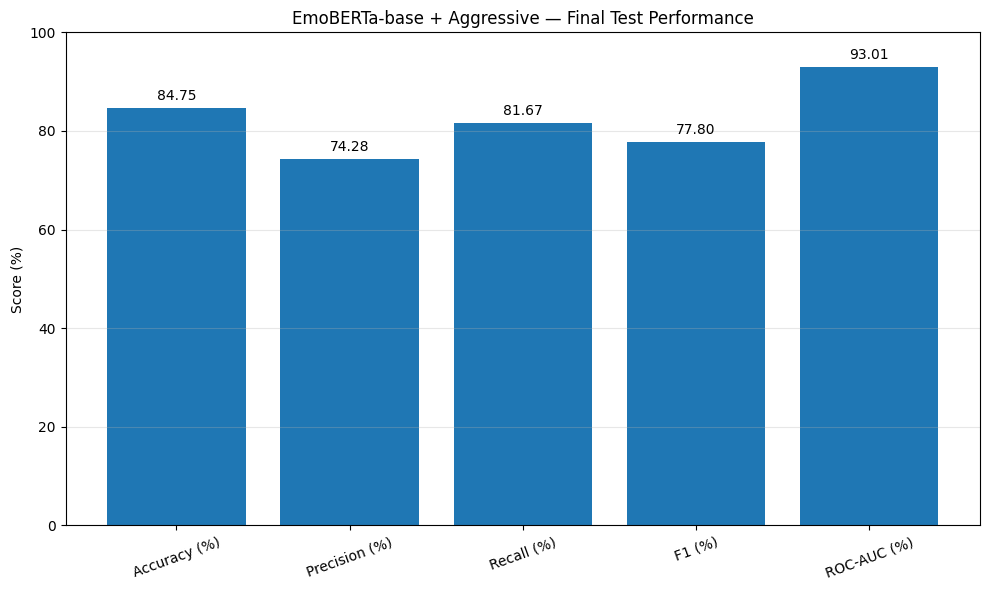

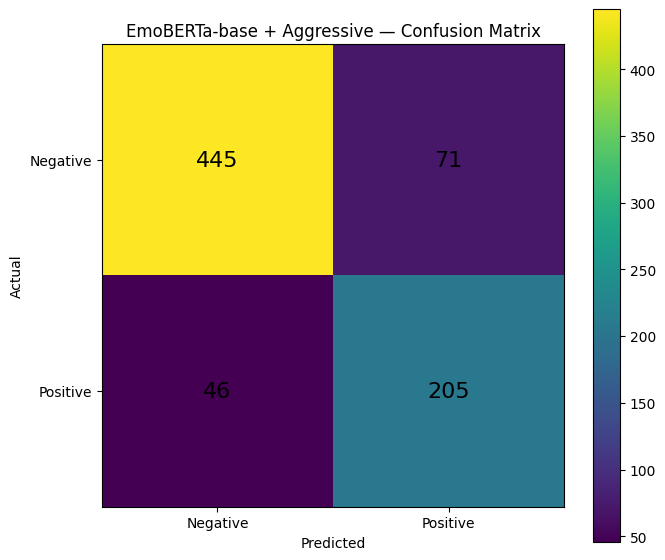

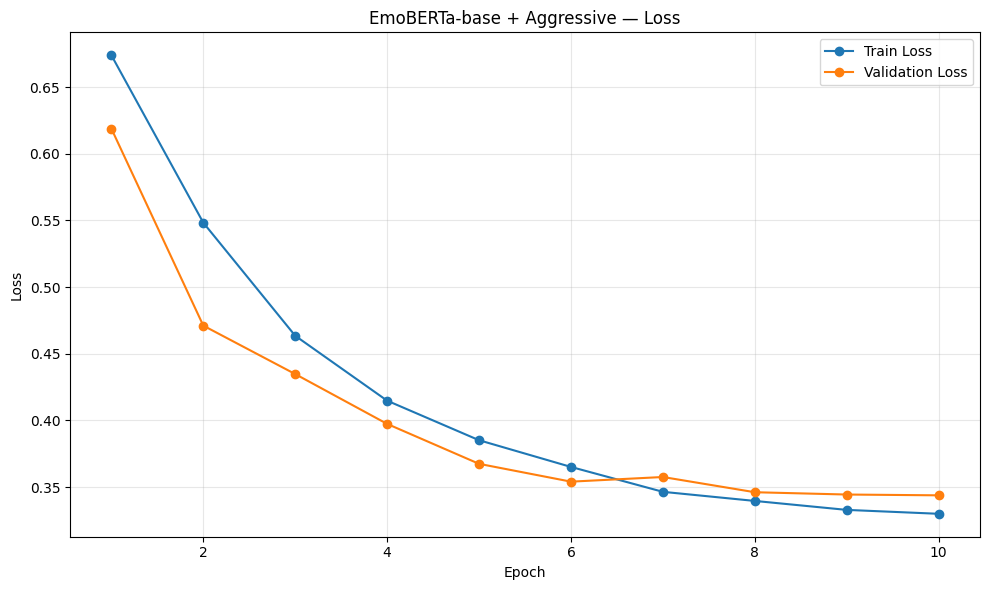

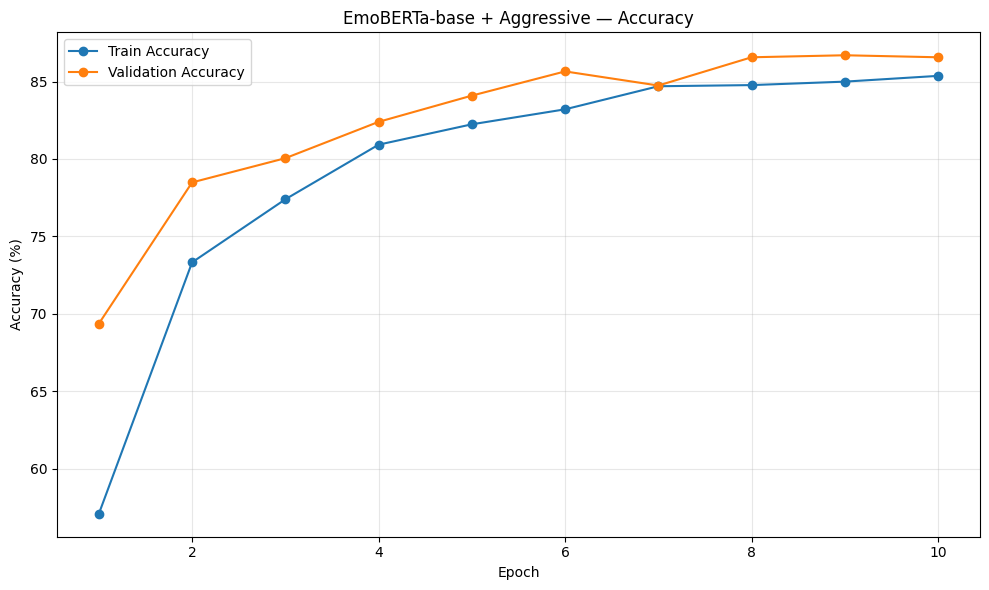

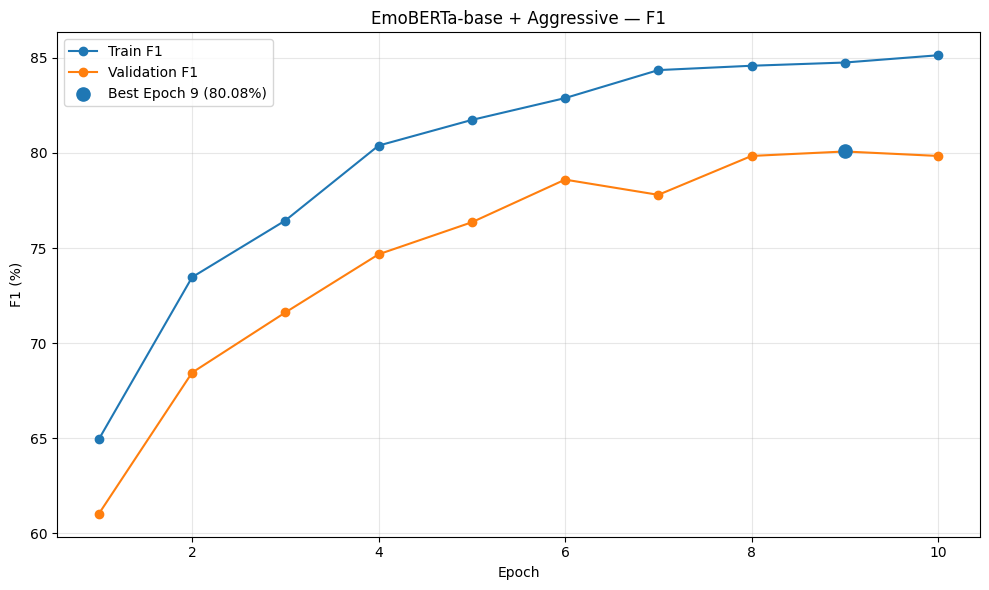

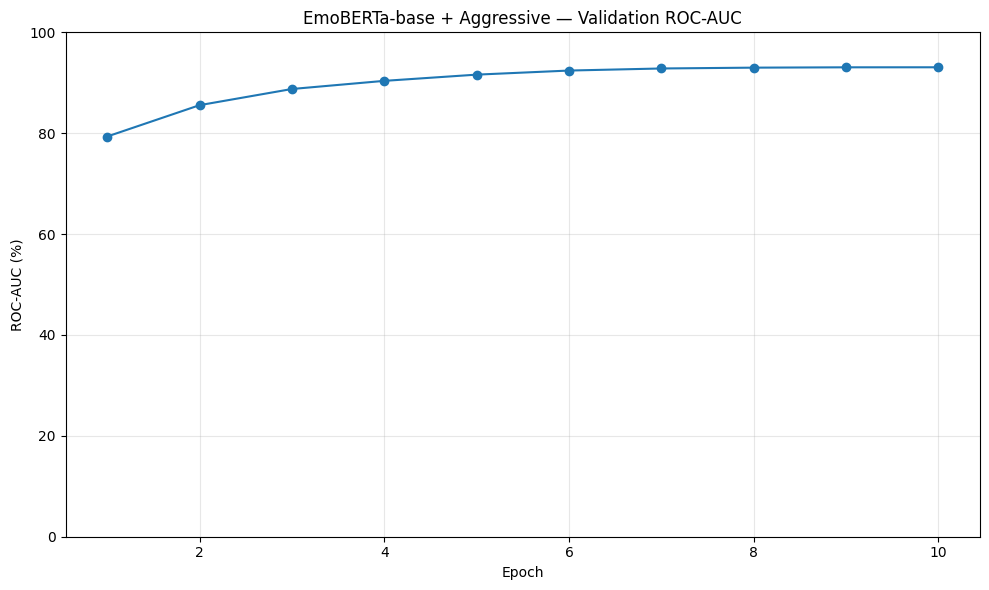

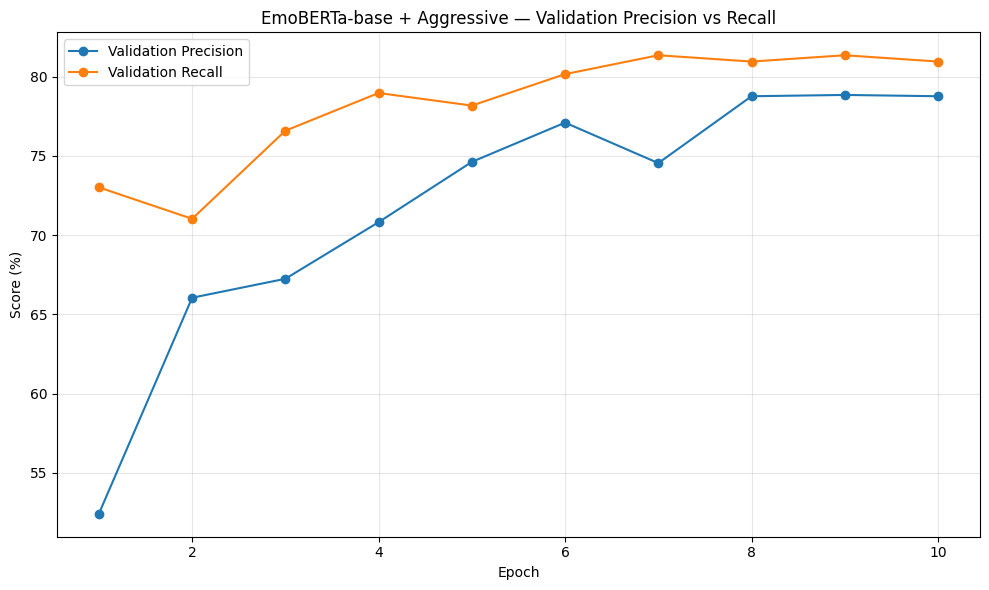

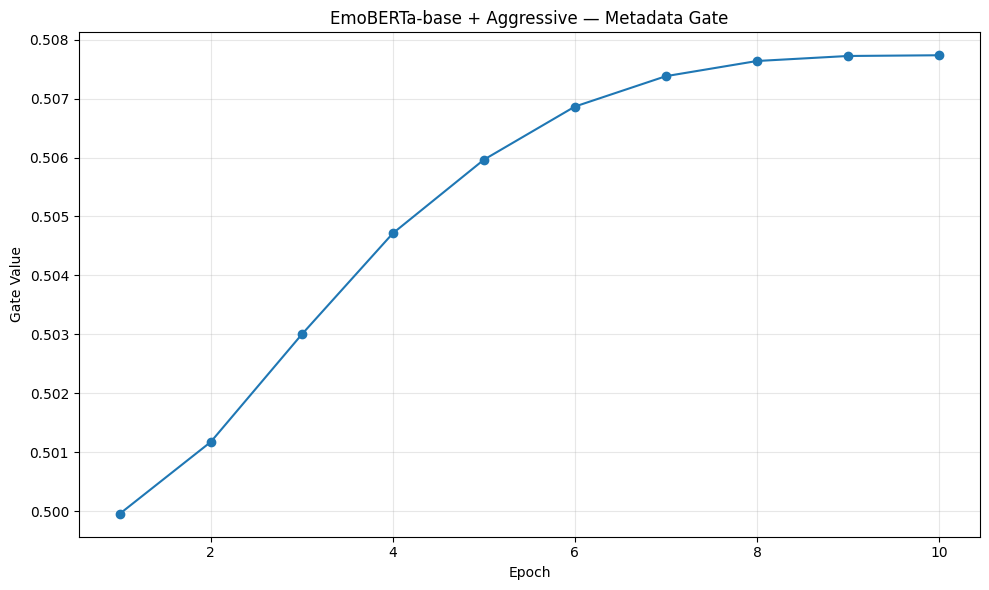

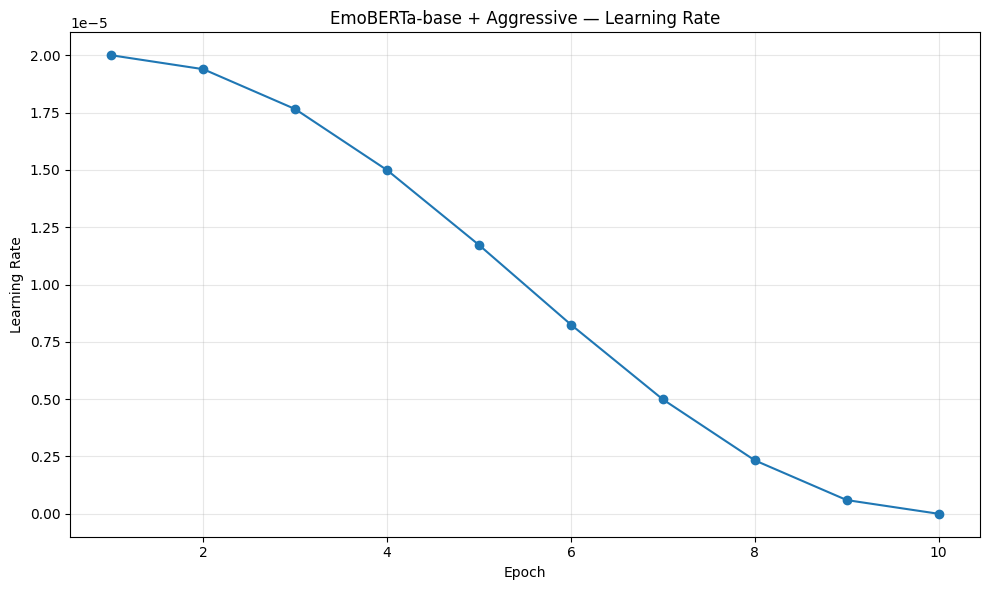

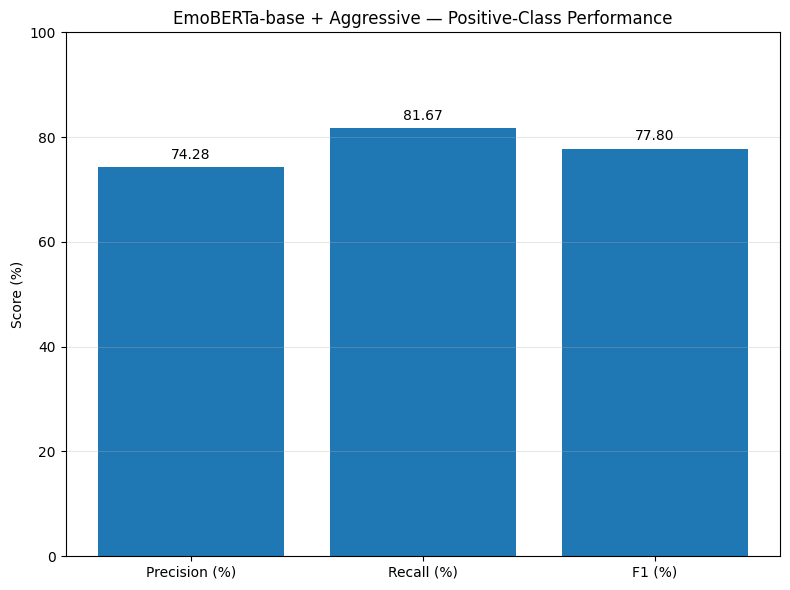

ValueError: All arrays must be of the same length

In [16]:
# ============================================================
# EMOBERTA-BASE + AGGRESSIVE
# COMPLETE RESULTS — GRAPHS + TABLES
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

RESULT_DIR = (
    "/kaggle/working/"
    "emoberta_aggressive/results"
)

GRAPH_DIR = os.path.join(
    RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    RESULT_DIR,
    "tables"
)

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)


# ============================================================
# REQUIRED FILES
# ============================================================

metrics_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_test_metrics.csv"
)

history_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_training_history.csv"
)

cm_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_confusion_matrix.csv"
)

report_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_classification_report.txt"
)

final_json_path = os.path.join(
    RESULT_DIR,
    "emoberta_aggressive_final_results.json"
)

assert os.path.exists(metrics_path)
assert os.path.exists(history_path)
assert os.path.exists(cm_path)
assert os.path.exists(report_path)
assert os.path.exists(final_json_path)


# ============================================================
# LOAD
# ============================================================

metrics_df = pd.read_csv(
    metrics_path
)

history_df = pd.read_csv(
    history_path
)

cm_df = pd.read_csv(
    cm_path,
    index_col=0
)

with open(
    report_path,
    "r",
    encoding="utf-8"
) as f:

    classification_report_text = (
        f.read()
    )

with open(
    final_json_path,
    "r",
    encoding="utf-8"
) as f:

    final_results = json.load(f)


# ============================================================
# 1. FINAL METRICS TABLE
# ============================================================

final_metrics_table = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Score (%)": [

        metrics_df.iloc[0]["Accuracy (%)"],

        metrics_df.iloc[0]["Precision (%)"],

        metrics_df.iloc[0]["Recall (%)"],

        metrics_df.iloc[0]["F1 (%)"],

        metrics_df.iloc[0]["ROC-AUC (%)"]
    ]
})


final_metrics_table[
    "Score (%)"
] = final_metrics_table[
    "Score (%)"
].round(2)


final_metrics_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "01_final_test_metrics_table.csv"
    ),
    index=False
)


# ============================================================
# 2. CONFUSION MATRIX TABLE
# ============================================================

cm_table = cm_df.copy()

cm_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "02_confusion_matrix_table.csv"
    )
)


# ============================================================
# 3. CLASSIFICATION REPORT TABLE
# ============================================================

report_lines = (
    classification_report_text
    .splitlines()
)

with open(
    os.path.join(
        TABLE_DIR,
        "03_classification_report.txt"
    ),
    "w",
    encoding="utf-8"
) as f:

    f.write(
        classification_report_text
    )


# ============================================================
# 4. TRAINING HISTORY TABLE
# ============================================================

history_table = history_df.copy()

history_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "04_training_history_table.csv"
    ),
    index=False
)


# ============================================================
# 5. EXPERIMENT SUMMARY TABLE
# ============================================================

experiment_summary = pd.DataFrame([{

    "Model":
        "EmoBERTa-base",

    "Cleaning":
        "Aggressive",

    "Transformer":
        "Frozen",

    "Context Length":
        512,

    "Metadata Features":
        53,

    "Balanced Train":
        4026,

    "Validation":
        767,

    "Test":
        767,

    "Best Epoch":
        final_results[
            "best_epoch"
        ],

    "Best Val F1 (%)":
        final_results[
            "best_validation_f1"
        ] * 100,

    "Test Accuracy (%)":
        final_results[
            "accuracy"
        ] * 100,

    "Test Precision (%)":
        final_results[
            "precision"
        ] * 100,

    "Test Recall (%)":
        final_results[
            "recall"
        ] * 100,

    "Test F1 (%)":
        final_results[
            "f1"
        ] * 100,

    "Test ROC-AUC (%)":
        final_results[
            "roc_auc"
        ] * 100,

    "TN":
        final_results["tn"],

    "FP":
        final_results["fp"],

    "FN":
        final_results["fn"],

    "TP":
        final_results["tp"]
}])


experiment_summary = (
    experiment_summary.round(4)
)

experiment_summary.to_csv(
    os.path.join(
        TABLE_DIR,
        "05_experiment_summary.csv"
    ),
    index=False
)


# ============================================================
# 6. FINAL TEST METRICS GRAPH
# ============================================================

metric_names = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "ROC-AUC (%)"
]

metric_values = [
    float(
        metrics_df.iloc[0][m]
    )
    for m in metric_names
]


plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    metric_names,
    metric_values
)

plt.title(
    "EmoBERTa-base + Aggressive — Final Test Performance"
)

plt.ylabel(
    "Score (%)"
)

plt.ylim(
    0,
    100
)

plt.xticks(
    rotation=20
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "01_final_test_performance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 7. CONFUSION MATRIX GRAPH
# ============================================================

cm = cm_df.values.astype(int)

plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "EmoBERTa-base + Aggressive — Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "02_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 8. TRAIN / VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title(
    "EmoBERTa-base + Aggressive — Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "03_training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. TRAIN / VALIDATION ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.title(
    "EmoBERTa-base + Aggressive — Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy (%)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "04_training_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. TRAIN / VALIDATION F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_f1"] * 100,
    marker="o",
    label="Train F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="o",
    label="Validation F1"
)

best_idx = (
    history_df["val_f1"]
    .idxmax()
)

best_epoch = int(
    history_df.loc[
        best_idx,
        "epoch"
    ]
)

best_f1 = float(
    history_df.loc[
        best_idx,
        "val_f1"
    ] * 100
)

plt.scatter(
    [best_epoch],
    [best_f1],
    s=90,
    zorder=5,
    label=(
        f"Best Epoch {best_epoch} "
        f"({best_f1:.2f}%)"
    )
)

plt.title(
    "EmoBERTa-base + Aggressive — F1"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "F1 (%)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "05_training_validation_f1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. VALIDATION ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"] * 100,
    marker="o"
)

plt.title(
    "EmoBERTa-base + Aggressive — Validation ROC-AUC"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "ROC-AUC (%)"
)

plt.ylim(
    0,
    100
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "06_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 12. VALIDATION PRECISION / RECALL
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["val_precision"] * 100,
    marker="o",
    label="Validation Precision"
)

plt.plot(
    history_df["epoch"],
    history_df["val_recall"] * 100,
    marker="o",
    label="Validation Recall"
)

plt.title(
    "EmoBERTa-base + Aggressive — Validation Precision vs Recall"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Score (%)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "07_validation_precision_recall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 13. METADATA GATE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["metadata_gate"],
    marker="o"
)

plt.title(
    "EmoBERTa-base + Aggressive — Metadata Gate"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Gate Value"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "08_metadata_gate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 14. LEARNING RATE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["learning_rate"],
    marker="o"
)

plt.title(
    "EmoBERTa-base + Aggressive — Learning Rate"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Learning Rate"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "09_learning_rate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 15. POSITIVE CLASS PERFORMANCE
# ============================================================

positive_names = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)"
]

positive_values = [
    float(
        metrics_df.iloc[0][x]
    )
    for x in positive_names
]


plt.figure(
    figsize=(8, 6)
)

bars = plt.bar(
    positive_names,
    positive_values
)

plt.title(
    "EmoBERTa-base + Aggressive — Positive-Class Performance"
)

plt.ylabel(
    "Score (%)"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    positive_values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "10_positive_class_performance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# GRAPH INDEX
# ============================================================

graph_index = pd.DataFrame({

    "Figure": [
        "01_final_test_performance.png",
        "02_confusion_matrix.png",
        "03_training_validation_loss.png",
        "04_training_validation_accuracy.png",
        "05_training_validation_f1.png",
        "06_validation_roc_auc.png",
        "07_validation_precision_recall.png",
        "08_metadata_gate.png",
        "09_learning_rate.png",
        "10_positive_class_performance.png"
    ],

    "Description": [
        "Final Accuracy, Precision, Recall, F1 and ROC-AUC",
        "Final test confusion matrix",
        "Training vs validation loss",
        "Training vs validation accuracy",
        "Training vs validation F1",
        "Validation ROC-AUC",
        "Validation precision vs recall",
        "Learned metadata gate",
        "Learning-rate schedule",
        "Positive-class precision, recall and F1"
    ]
})


graph_index.to_csv(
    os.path.join(
        GRAPH_DIR,
        "graph_index.csv"
    ),
    index=False
)


# ============================================================
# FINAL RESULTS INDEX
# ============================================================

results_index = pd.DataFrame({

    "Type": [
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Graph",
        "Table",
        "Table",
        "Table",
        "Table",
        "Table"
    ],

    "File": [
        "graphs/01_final_test_performance.png",
        "graphs/02_confusion_matrix.png",
        "graphs/03_training_validation_loss.png",
        "graphs/04_training_validation_accuracy.png",
        "graphs/05_training_validation_f1.png",
        "graphs/06_validation_roc_auc.png",
        "graphs/07_validation_precision_recall.png",
        "graphs/08_metadata_gate.png",
        "graphs/09_learning_rate.png",
        "graphs/10_positive_class_performance.png",
        "tables/01_final_test_metrics_table.csv",
        "tables/02_confusion_matrix_table.csv",
        "tables/03_classification_report.txt",
        "tables/04_training_history_table.csv",
        "tables/05_experiment_summary.csv",
        "graphs/graph_index.csv"
    ]
})


results_index.to_csv(
    os.path.join(
        RESULT_DIR,
        "results_index.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 70)
print("EMOBERTA-BASE + AGGRESSIVE — RESULTS SAVED")
print("=" * 70)

print()

print(
    "Graphs:",
    GRAPH_DIR
)

print(
    "Tables:",
    TABLE_DIR
)

print()

print(
    "Best Epoch:",
    final_results["best_epoch"]
)

print(
    "Best Validation F1:",
    f"{final_results['best_validation_f1'] * 100:.2f}%"
)

print(
    "Test Accuracy:",
    f"{final_results['accuracy'] * 100:.2f}%"
)

print(
    "Test F1:",
    f"{final_results['f1'] * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{final_results['roc_auc'] * 100:.2f}%"
)

print()

print(
    "✓ All graphs saved"
)

print(
    "✓ All result tables saved"
)

print(
    "✓ Classification report saved"
)

print(
    "✓ Training history saved"
)

print(
    "✓ Results index saved"
)

In [17]:
# ============================================================
# FIX — RESULTS INDEX
# ============================================================

import os
import pandas as pd

RESULT_DIR = "/kaggle/working/emoberta_aggressive/results"

GRAPH_DIR = os.path.join(
    RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    RESULT_DIR,
    "tables"
)

# ------------------------------------------------------------
# Build using paired rows so lengths can never mismatch
# ------------------------------------------------------------

result_items = [

    ("Graph",
     "graphs/01_final_test_performance.png"),

    ("Graph",
     "graphs/02_confusion_matrix.png"),

    ("Graph",
     "graphs/03_training_validation_loss.png"),

    ("Graph",
     "graphs/04_training_validation_accuracy.png"),

    ("Graph",
     "graphs/05_training_validation_f1.png"),

    ("Graph",
     "graphs/06_validation_roc_auc.png"),

    ("Graph",
     "graphs/07_validation_precision_recall.png"),

    ("Graph",
     "graphs/08_metadata_gate.png"),

    ("Graph",
     "graphs/09_learning_rate.png"),

    ("Graph",
     "graphs/10_positive_class_performance.png"),

    ("Table",
     "tables/01_final_test_metrics_table.csv"),

    ("Table",
     "tables/02_confusion_matrix_table.csv"),

    ("Table",
     "tables/03_classification_report.txt"),

    ("Table",
     "tables/04_training_history_table.csv"),

    ("Table",
     "tables/05_experiment_summary.csv")
]


results_index = pd.DataFrame(
    result_items,
    columns=[
        "Type",
        "File"
    ]
)


# ------------------------------------------------------------
# Verify only existing files are indexed
# ------------------------------------------------------------

results_index["Exists"] = (
    results_index["File"]
    .apply(
        lambda x:
        os.path.exists(
            os.path.join(
                RESULT_DIR,
                x
            )
        )
    )
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

results_index.to_csv(
    os.path.join(
        RESULT_DIR,
        "results_index.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("=" * 60)
print("RESULTS INDEX FIXED")
print("=" * 60)

print()

print(
    results_index.to_string(
        index=False
    )
)

print()

print(
    "Existing files:",
    int(
        results_index["Exists"].sum()
    ),
    "/",
    len(results_index)
)

assert results_index["Exists"].all()

print()
print(
    "✓ All indexed graphs/tables exist"
)

print(
    "✓ results_index.csv saved"
)

RESULTS INDEX FIXED

 Type                                       File  Exists
Graph       graphs/01_final_test_performance.png    True
Graph             graphs/02_confusion_matrix.png    True
Graph     graphs/03_training_validation_loss.png    True
Graph graphs/04_training_validation_accuracy.png    True
Graph       graphs/05_training_validation_f1.png    True
Graph           graphs/06_validation_roc_auc.png    True
Graph  graphs/07_validation_precision_recall.png    True
Graph                graphs/08_metadata_gate.png    True
Graph                graphs/09_learning_rate.png    True
Graph   graphs/10_positive_class_performance.png    True
Table     tables/01_final_test_metrics_table.csv    True
Table       tables/02_confusion_matrix_table.csv    True
Table        tables/03_classification_report.txt    True
Table       tables/04_training_history_table.csv    True
Table           tables/05_experiment_summary.csv    True

Existing files: 15 / 15

✓ All indexed graphs/tables exist
✓ resul

In [18]:
# ============================================================
# TABLES — EMOBERTA-BASE + AGGRESSIVE
# ============================================================

# Load results

with open(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_final_results.json"
    ),
    "r"
) as f:

    final_results = json.load(f)

metrics_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_test_metrics.csv"
    )
)

history_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_aggressive_training_history.csv"
    )
)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

best_epoch = int(
    final_results["best_epoch"]
)

best_epoch_row = history_df[
    history_df["epoch"] == best_epoch
].iloc[0]

results_table = pd.DataFrame({
    "Model": ["EmoBERTa-base"],
    "Cleaning": ["Aggressive"],
    "Train Accuracy": [
        best_epoch_row["train_accuracy"] * 100
    ],
    "Validation Accuracy": [
        best_epoch_row["val_accuracy"] * 100
    ],
    "Test Accuracy": [
        final_results["accuracy"] * 100
    ],
    "Precision": [
        final_results["precision"] * 100
    ],
    "Recall": [
        final_results["recall"] * 100
    ],
    "F1-Score": [
        final_results["f1"] * 100
    ],
    "ROC-AUC": [
        final_results["roc_auc"] * 100
    ]
}).round(2)

print()
print("=" * 60)
print("FINAL RESULTS TABLE")
print("=" * 60)

print(
    results_table.to_string(
        index=False
    )
)

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "emoberta_aggressive_results_table.csv"
    ),
    index=False
)

# ============================================================
# TRAINING HISTORY TABLE
# ============================================================

history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "emoberta_aggressive_training_history_table.csv"
    ),
    index=False
)

# ============================================================
# CONFUSION MATRIX TABLE
# ============================================================

cm_df = pd.DataFrame(
    final_results["confusion_matrix"],
    index=[
        "Actual Negative",
        "Actual Positive"
    ],
    columns=[
        "Predicted Negative",
        "Predicted Positive"
    ]
)

cm_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "emoberta_aggressive_confusion_matrix_table.csv"
    )
)

# ============================================================
# SUMMARY FILE
# ============================================================

with open(
    os.path.join(
        TABLE_DIR,
        "emoberta_aggressive_summary.txt"
    ),
    "w"
) as f:

    f.write(
        "EMOBERTA-BASE + AGGRESSIVE — FINAL RESULTS\n"
    )

    f.write(
        "===========================================\n"
    )

    f.write(
        f"Train Accuracy      : "
        f"{best_epoch_row['train_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Validation Accuracy : "
        f"{best_epoch_row['val_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Test Accuracy       : "
        f"{final_results['accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision           : "
        f"{final_results['precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall              : "
        f"{final_results['recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1-Score            : "
        f"{final_results['f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC             : "
        f"{final_results['roc_auc'] * 100:.2f}%\n"
    )

    f.write(
        "\nConfusion Matrix:\n"
    )

    f.write(
        f"TN={final_results['tn']}, "
        f"FP={final_results['fp']}\n"
    )

    f.write(
        f"FN={final_results['fn']}, "
        f"TP={final_results['tp']}\n"
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("TABLES COMPLETE")
print("=" * 60)

print(
    "✓ Final results table saved"
)

print(
    "✓ Training history table saved"
)

print(
    "✓ Confusion matrix table saved"
)

print(
    "✓ Summary file saved"
)

print()
print(
    "Tables:",
    TABLE_DIR
)


FINAL RESULTS TABLE
        Model   Cleaning  Train Accuracy  Validation Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
EmoBERTa-base Aggressive            85.0                 86.7          84.75      74.28   81.67      77.8    93.01


KeyError: 'confusion_matrix'

t-SNE REPRESENTATION ANALYSIS
EMOBERTA-BASE + AGGRESSIVE

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 87.92%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


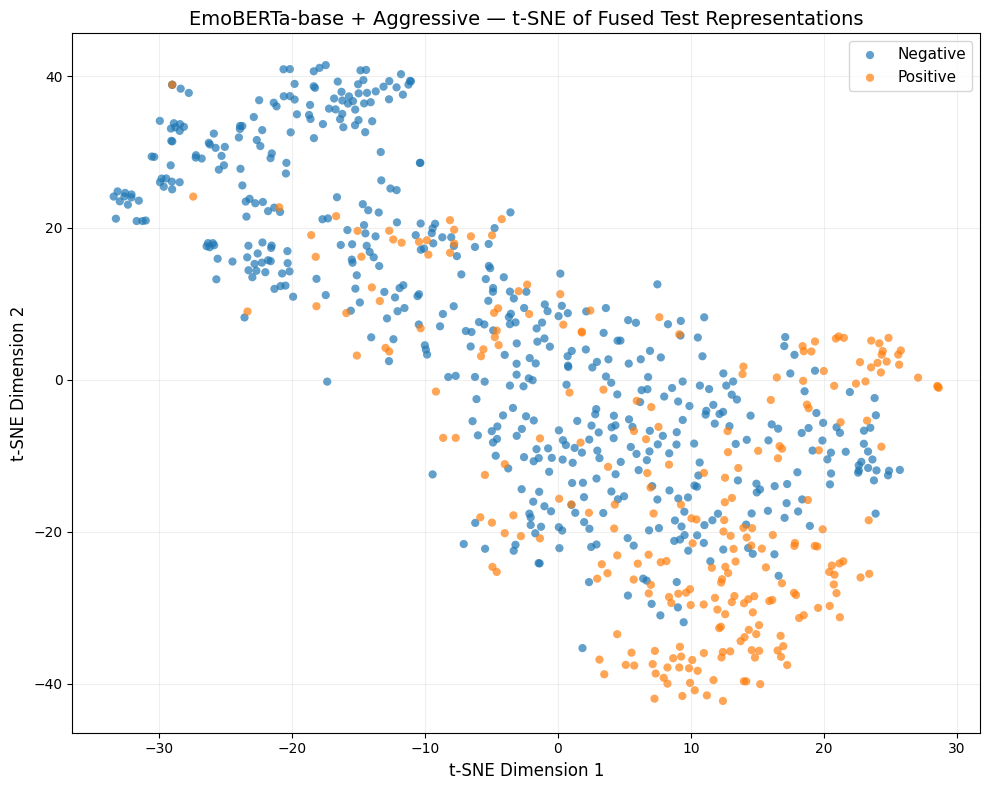


t-SNE ANALYSIS COMPLETE
✓ Fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/emoberta_aggressive/explainability/tsne/emoberta_aggressive_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/emoberta_aggressive/explainability/tsne/emoberta_aggressive_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [19]:
# ============================================================
# EXPLAINABILITY — CELL 1
# EMOBERTA-BASE + AGGRESSIVE
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("EMOBERTA-BASE + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42
PCA_COMPONENTS = 50
TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_emoberta_aggressive.eval()

# ============================================================
# EXTRACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print(
    "Extracting fused model representations..."
)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_emoberta_aggressive_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_emoberta_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # ----------------------------------------------------
        # ACTUAL OUTPUT NAMES FROM EMOBERTA MODEL
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]

        metadata_representation = output[
            "metadata_representation"
        ]

        # ----------------------------------------------------
        # SAME LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_emoberta_aggressive.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(
                test_emoberta_aggressive_loader
            )
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/"
                f"{len(test_emoberta_aggressive_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "emoberta_aggressive_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Aggressive — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "emoberta_aggressive_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED

}

with open(
    os.path.join(
        TSNE_DIR,
        "emoberta_aggressive_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
EMOBERTA-BASE + AGGRESSIVE

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ EmoBERTa-base model set to evaluation mode
✓ No parameters will be updated

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                 feature  mean_abs_shap  mean_signed_shap
             tweet_count       0.030153          0.001132
             lda_topic_2       0.029349          0.004508
             lda_topic_9       0.023047          0.004645
            lda_topic_13       0.019803         -0.004040
              word_count       0.

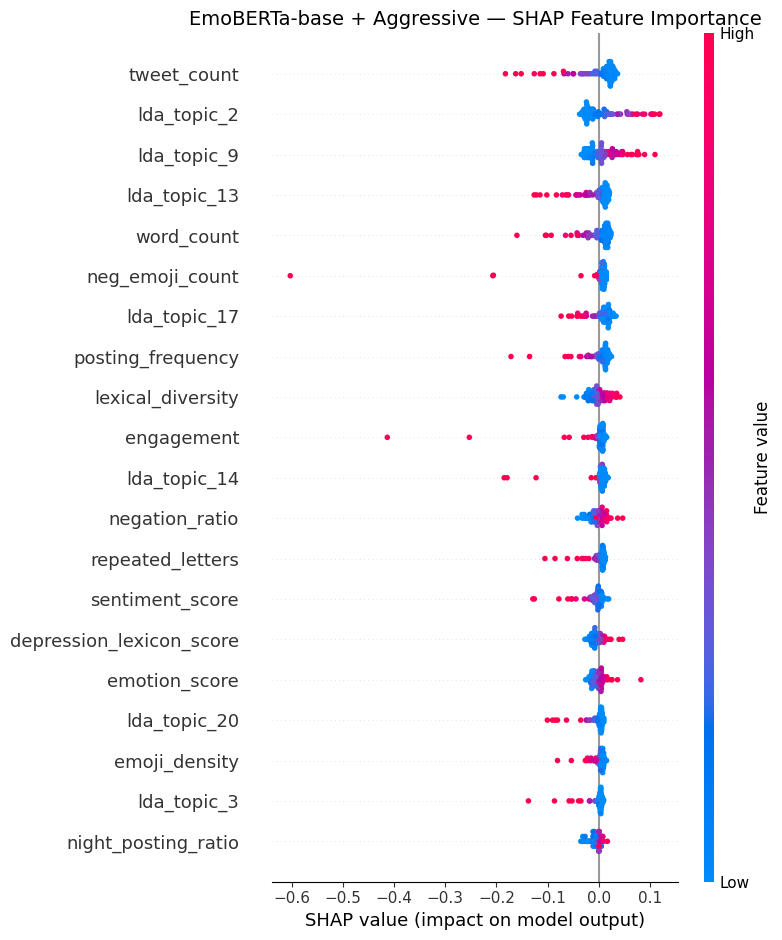

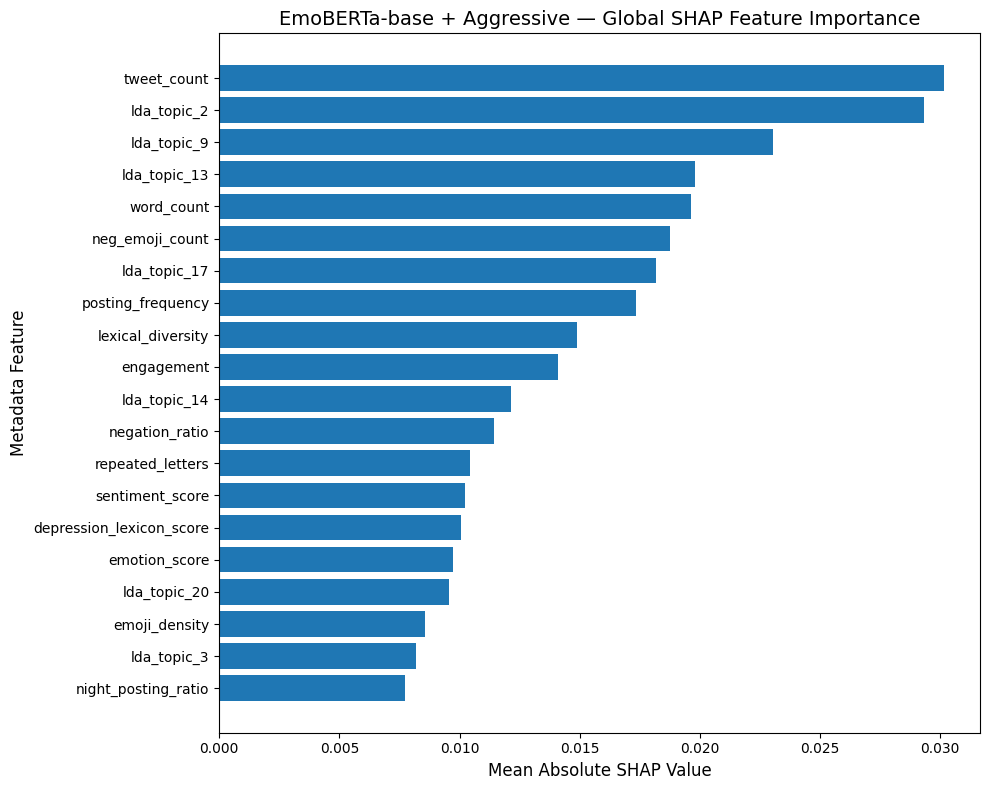


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 100 fixed test users explained
✓ 50 negative + 50 positive
✓ Training-only background used
✓ Positive-class logit explained
✓ EmoBERTa-base weights unchanged
✓ SHAP beeswarm saved and displayed
✓ SHAP bar plot saved and displayed
✓ SHAP values saved
✓ Feature importance ranking saved
✓ Configuration saved

SHAP output directory: /kaggle/working/emoberta_aggressive/explainability/shap


In [20]:
# ============================================================
# EXPLAINABILITY — SHAP
# EMOBERTA-BASE + AGGRESSIVE
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("EMOBERTA-BASE + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(
    SHAP_SEED
)

torch.manual_seed(
    SHAP_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)

# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_emoberta_aggressive_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53

# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_emoberta_aggressive_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert (
    len(negative_indices)
    >= SHAP_TEST_SIZE_PER_CLASS
)

assert (
    len(positive_indices)
    >= SHAP_TEST_SIZE_PER_CLASS
)

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)

# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Transformer text representation fixed.
# No model parameters are changed.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids
            .to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask
            .to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = (
            metadata.size(0)
        )

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# ============================================================

model_emoberta_aggressive.eval()

for parameter in (
    model_emoberta_aggressive.parameters()
):

    parameter.requires_grad = False

print()
print(
    "✓ EmoBERTa-base model set to evaluation mode"
)

print(
    "✓ No parameters will be updated"
)

# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_emoberta_aggressive_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )

    # --------------------------------------------------------
    # User-specific wrapper
    # Text representation remains fixed for this user.
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model_emoberta_aggressive,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()

    # --------------------------------------------------------
    # Gradient-based SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )

    # --------------------------------------------------------
    # Handle SHAP version-dependent output format
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )

    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )

    if (
        count == 1
        or count % 10 == 0
        or count == len(shap_test_indices)
    ):

        print(
            f"Explained "
            f"{count}/{len(shap_test_indices)} "
            f"test users"
        )

# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(all_shap_values),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)

# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_aggressive_shap_values.csv"
    ),
    index=False
)

# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_aggressive_shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SAVE EXPLAINED USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_aggressive_shap_test_users.csv"
    ),
    index=False
)

# ============================================================
# SHAP BEESWARM — PAPER FIGURE
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "EmoBERTa-base + Aggressive — "
    "SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "emoberta_aggressive_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SHAP BAR — PAPER FIGURE
# ============================================================

top_features = (
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Aggressive — "
    "Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "emoberta_aggressive_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "total_metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_test_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "SHAP GradientExplainer",

    "text_representation":
        "Fixed for each explained user",

    "random_seed":
        SHAP_SEED,

    "top_features_displayed":
        SHAP_TOP_FEATURES

}

with open(
    os.path.join(
        SHAP_DIR,
        "emoberta_aggressive_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features explained"
)

print(
    "✓ 100 fixed test users explained"
)

print(
    "✓ 50 negative + 50 positive"
)

print(
    "✓ Training-only background used"
)

print(
    "✓ Positive-class logit explained"
)

print(
    "✓ EmoBERTa-base weights unchanged"
)

print(
    "✓ SHAP beeswarm saved and displayed"
)

print(
    "✓ SHAP bar plot saved and displayed"
)

print(
    "✓ SHAP values saved"
)

print(
    "✓ Feature importance ranking saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

GRAD-CAM ANALYSIS
EMOBERTA-BASE + AGGRESSIVE

✓ EmoBERTa-base model loaded
✓ Evaluation mode enabled
✓ All model parameters remain frozen

FIXED REPRESENTATIVE TEST CASES
TP: test index = 1 | true = 1 | pred = 1 | probability = 0.7472
TN: test index = 0 | true = 0 | pred = 0 | probability = 0.3463
FP: test index = 8 | true = 0 | pred = 1 | probability = 0.5054
FN: test index = 23 | true = 1 | pred = 0 | probability = 0.3670

GENERATING GRAD-CAM EXPLANATIONS

Processing TP (test index 1)...
✓ TP Grad-CAM complete

Processing TN (test index 0)...
✓ TN Grad-CAM complete

Processing FP (test index 8)...
✓ FP Grad-CAM complete

Processing FN (test index 23)...
✓ FN Grad-CAM complete

GRAD-CAM TOKEN IMPORTANCE


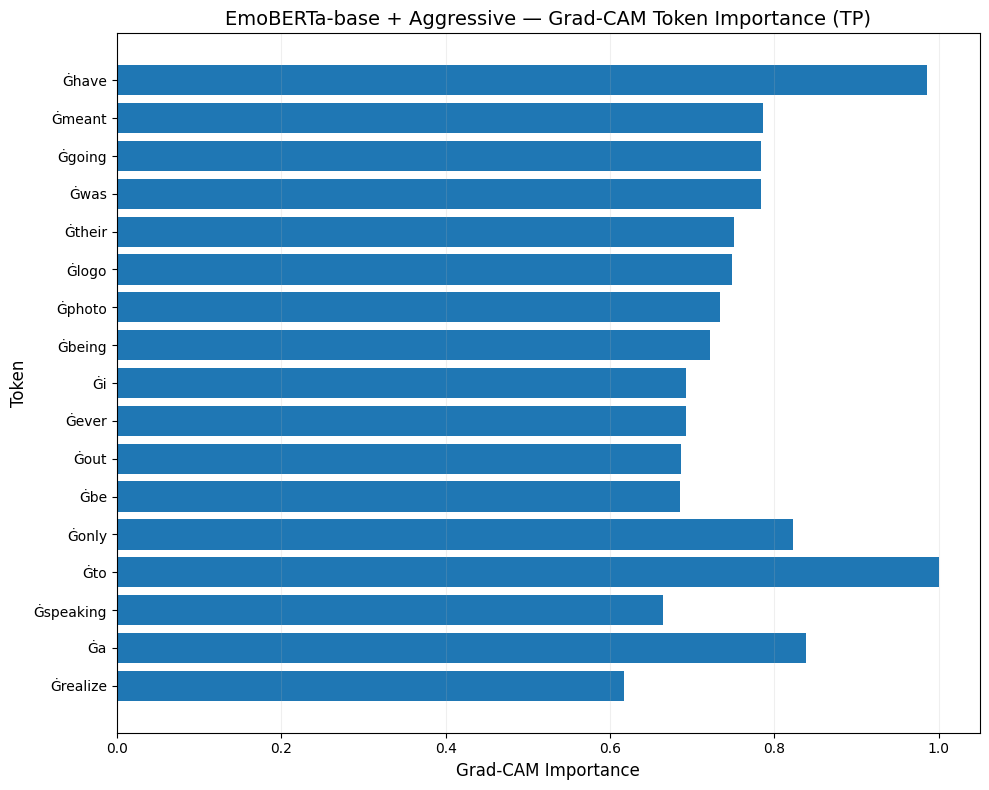

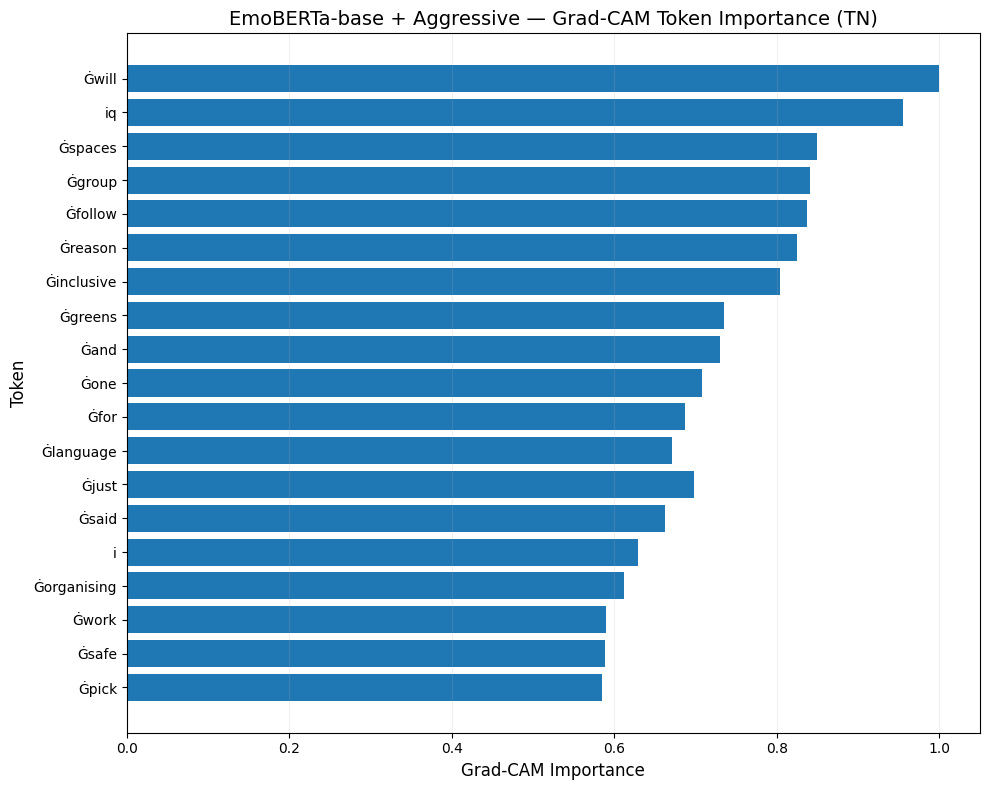

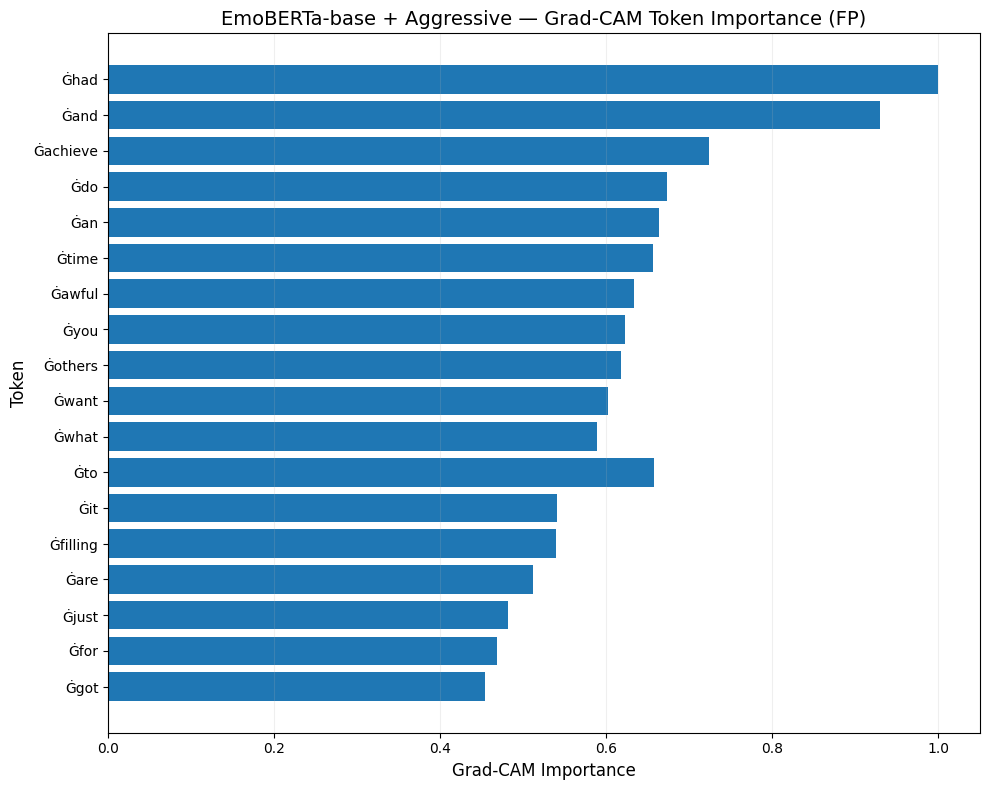

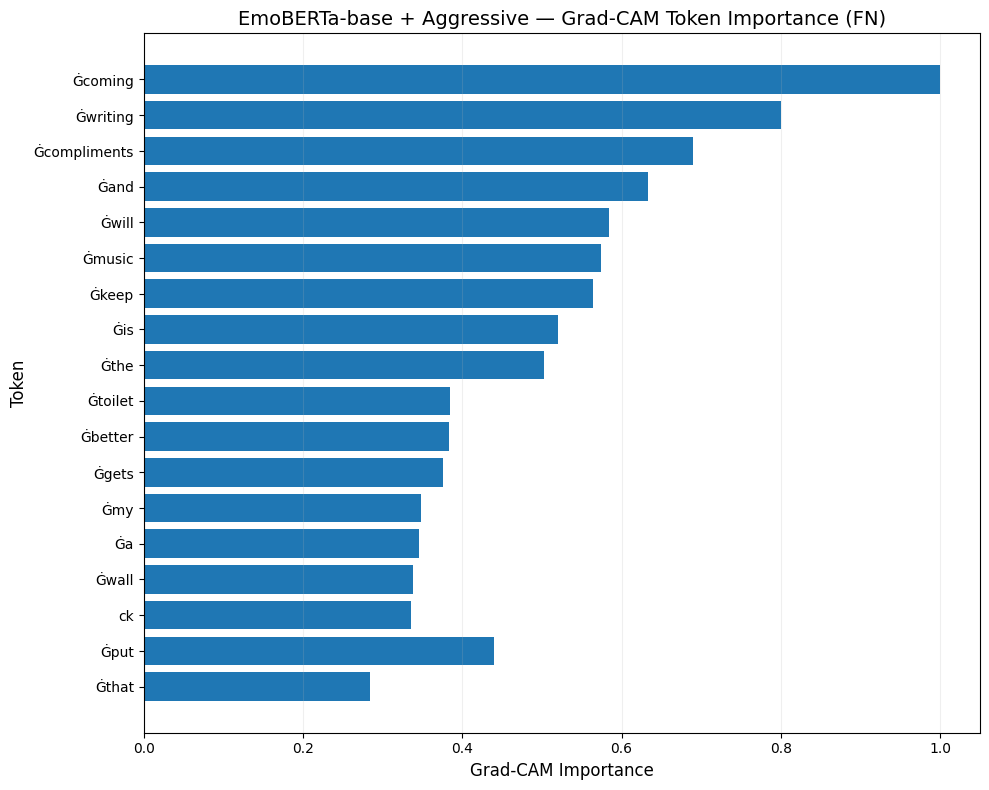


GRAD-CAM ANALYSIS COMPLETE
✓ Same TP/TN/FP/FN selection logic used
✓ Final Transformer hidden states used
✓ Positive-class gradients computed
✓ EmoBERTa-base weights remained frozen
✓ No additional model training
✓ Token importance calculated
✓ Top-20 token plots saved and displayed
✓ Token importance CSV saved
✓ Configuration saved

Grad-CAM output directory: /kaggle/working/emoberta_aggressive/explainability/gradcam


In [21]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# EMOBERTA-BASE + AGGRESSIVE
# TOKEN-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display, HTML

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("EMOBERTA-BASE + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_emoberta_aggressive.eval()

# Keep all model parameters frozen
for parameter in (
    model_emoberta_aggressive.parameters()
):

    parameter.requires_grad = False

print()
print("✓ EmoBERTa-base model loaded")
print("✓ Evaluation mode enabled")
print("✓ All model parameters remain frozen")

# ============================================================
# BUILD TEST PREDICTIONS
# DIRECTLY FROM NOTEBOOK TEST LOADER
# ============================================================

test_labels = []
test_predictions = []
test_probabilities = []

with torch.no_grad():

    for batch in test_emoberta_aggressive_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_emoberta_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        test_labels.extend(
            labels
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

test_labels = np.array(
    test_labels
)

test_predictions = np.array(
    test_predictions
)

test_probabilities = np.array(
    test_probabilities
)

# ============================================================
# SELECT TP / TN / FP / FN
# SAME FIRST-MATCHING TEST ORDER
# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (test_labels == 1)
    &
    (test_predictions == 1)
)[0]

tn_candidates = np.where(
    (test_labels == 0)
    &
    (test_predictions == 0)
)[0]

fp_candidates = np.where(
    (test_labels == 0)
    &
    (test_predictions == 1)
)[0]

fn_candidates = np.where(
    (test_labels == 1)
    &
    (test_predictions == 0)
)[0]

if len(tp_candidates) > 0:
    selected_cases["TP"] = int(
        tp_candidates[0]
    )

if len(tn_candidates) > 0:
    selected_cases["TN"] = int(
        tn_candidates[0]
    )

if len(fp_candidates) > 0:
    selected_cases["FP"] = int(
        fp_candidates[0]
    )

if len(fn_candidates) > 0:
    selected_cases["FN"] = int(
        fn_candidates[0]
    )

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index} | "
        f"true = {test_labels[test_index]} | "
        f"pred = {test_predictions[test_index]} | "
        f"probability = "
        f"{test_probabilities[test_index]:.4f}"
    )

# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_emoberta_gradcam(
    test_index
):

    sample = test_emoberta_aggressive_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # Encoder forward pass
    # --------------------------------------------------------
    # Encoder parameters are frozen, but gradients are enabled
    # with respect to the hidden-state activation.
    # --------------------------------------------------------

    with torch.enable_grad():

        encoder_output = (
            model_emoberta_aggressive.emoberta(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # Required because encoder is frozen
        hidden_states = (
            hidden_states.detach()
        )

        hidden_states.requires_grad_(True)

        hidden_states.retain_grad()

        # ----------------------------------------------------
        # EXACT ATTENTION POOLING FROM MODEL
        # ----------------------------------------------------

        projected = torch.tanh(
            model_emoberta_aggressive.attention_projection(
                hidden_states
            )
        )

        scores = (
            model_emoberta_aggressive.attention_score(
                projected
            )
            .squeeze(-1)
        )

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH FROM MODEL
        # ----------------------------------------------------

        metadata_representation = (
            model_emoberta_aggressive.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model_emoberta_aggressive.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSION + CLASSIFIER
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = (
            model_emoberta_aggressive.classifier(
                fused
            )
        )

        # Positive/depression class
        target_score = logits[
            0,
            1
        ]

        # ----------------------------------------------------
        # BACKWARD
        # ----------------------------------------------------

        model_emoberta_aggressive.zero_grad(
            set_to_none=True
        )

        target_score.backward()

        gradients = (
            hidden_states.grad
            .detach()
            .clone()
        )

        activations = (
            hidden_states.detach()
            .clone()
        )

    # ========================================================
    # GRAD-CAM WEIGHTS
    # ========================================================

    # Global average pooling over token positions
    channel_weights = gradients.mean(
        dim=1
    )

    # Weighted combination of hidden-state channels
    cam = torch.sum(
        activations *
        channel_weights.unsqueeze(1),
        dim=-1
    )

    # Standard Grad-CAM ReLU
    cam = torch.relu(
        cam
    )

    cam = (
        cam
        .squeeze(0)
        .cpu()
        .numpy()
    )

    attention_weights_np = (
        attention_weights
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    input_ids_np = (
        input_ids
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Normalize Grad-CAM
    # --------------------------------------------------------

    valid_mask = (
        attention_mask
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
        .astype(bool)
    )

    valid_cam = cam[
        valid_mask
    ]

    if (
        valid_cam.max()
        -
        valid_cam.min()
    ) > 1e-12:

        cam_normalized = (
            cam
            -
            valid_cam.min()
        ) / (
            valid_cam.max()
            -
            valid_cam.min()
        )

    else:

        cam_normalized = (
            np.zeros_like(cam)
        )

    # Padding tokens must never receive attribution
    cam_normalized[
        ~valid_mask
    ] = 0.0

    return {
        "cam":
            cam_normalized,

        "attention_weights":
            attention_weights_np,

        "input_ids":
            input_ids_np,

        "attention_mask":
            valid_mask,

        "positive_logit":
            float(
                target_score
                .detach()
                .cpu()
                .item()
            ),

        "logits":
            logits
            .detach()
            .cpu()
            .numpy()
            .squeeze(0)
    }


# ============================================================
# TOKEN PROCESSING
# ============================================================

def get_token_information(
    result
):

    token_ids = (
        result["input_ids"]
    )

    cam = (
        result["cam"]
    )

    attention_mask = (
        result["attention_mask"]
    )

    tokens = emoberta_aggressive_tokenizer.convert_ids_to_tokens(
        token_ids.tolist()
    )

    rows = []

    for position, (
        token,
        importance,
        valid
    ) in enumerate(
        zip(
            tokens,
            cam,
            attention_mask
        )
    ):

        if not valid:
            continue

        # Ignore special tokens
        if (
            token
            in emoberta_aggressive_tokenizer.all_special_tokens
        ):
            continue

        rows.append({

            "position":
                position,

            "token":
                token,

            "importance":
                float(
                    importance
                )

        })

    token_df = pd.DataFrame(
        rows
    )

    token_df = (
        token_df
        .sort_values(
            "importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    token_df["rank"] = (
        np.arange(
            len(token_df)
        ) + 1
    )

    return token_df


# ============================================================
# RUN GRAD-CAM FOR TP/TN/FP/FN
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("GENERATING GRAD-CAM EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    result = compute_emoberta_gradcam(
        test_index
    )

    token_df = get_token_information(
        result
    )

    gradcam_results[
        case_name
    ] = {

        "test_index":
            test_index,

        "result":
            result,

        "token_df":
            token_df
    }

    print(
        f"✓ {case_name} Grad-CAM complete"
    )

# ============================================================
# SAVE TOKEN IMPORTANCE
# ============================================================

all_gradcam_rows = []

for case_name, data in gradcam_results.items():

    token_df = data[
        "token_df"
    ]

    for _, row in token_df.iterrows():

        all_gradcam_rows.append({

            "case":
                case_name,

            "test_index":
                data["test_index"],

            "true_label":
                int(
                    test_labels[
                        data["test_index"]
                    ]
                ),

            "predicted_label":
                int(
                    test_predictions[
                        data["test_index"]
                    ]
                ),

            "positive_probability":
                float(
                    test_probabilities[
                        data["test_index"]
                    ]
                ),

            "position":
                int(
                    row["position"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                ),

            "rank":
                int(
                    row["rank"]
                )

        })

gradcam_results_df = pd.DataFrame(
    all_gradcam_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "emoberta_aggressive_gradcam_token_importance.csv"
)

gradcam_results_df.to_csv(
    gradcam_csv_path,
    index=False
)

# ============================================================
# PAPER-READY TOP TOKEN PLOTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM TOKEN IMPORTANCE")
print("=" * 70)

for case_name, data in gradcam_results.items():

    token_df = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
        .copy()
    )

    # Reverse order so most important is at top
    token_df = token_df.iloc[::-1]

    plt.figure(
        figsize=(10, 8)
    )

    plt.barh(
        token_df["token"],
        token_df["importance"]
    )

    plt.xlabel(
        "Grad-CAM Importance",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"EmoBERTa-base + Aggressive — "
        f"Grad-CAM Token Importance ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"emoberta_aggressive_gradcam_{case_name}.png"
    )

    # SAVE
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    # DISPLAY
    plt.show()

    plt.close()

# ============================================================
# SAVE TOP TOKEN TABLE
# ============================================================

top_token_rows = []

for case_name, data in gradcam_results.items():

    top_tokens = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
    )

    for _, row in top_tokens.iterrows():

        top_token_rows.append({

            "case":
                case_name,

            "rank":
                int(
                    row["rank"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                )

        })

top_token_df = pd.DataFrame(
    top_token_rows
)

top_token_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "emoberta_aggressive_gradcam_top_tokens.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class logit",

    "layer":
        "Final Transformer hidden states",

    "hidden_dimension":
        768,

    "method":
        "Transformer Grad-CAM",

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"

}

with open(
    os.path.join(
        GRADCAM_DIR,
        "emoberta_aggressive_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Same TP/TN/FP/FN selection logic used"
)

print(
    "✓ Final Transformer hidden states used"
)

print(
    "✓ Positive-class gradients computed"
)

print(
    "✓ EmoBERTa-base weights remained frozen"
)

print(
    "✓ No additional model training"
)

print(
    "✓ Token importance calculated"
)

print(
    "✓ Top-20 token plots saved and displayed"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
EMOBERTA-BASE + AGGRESSIVE

✓ EmoBERTa-base model loaded
✓ Evaluation mode enabled

FIXED REPRESENTATIVE TEST CASES
TP: test index = 1 | true = 1 | pred = 1 | probability = 0.7472
TN: test index = 0 | true = 0 | pred = 0 | probability = 0.3463
FP: test index = 8 | true = 0 | pred = 1 | probability = 0.5054
FN: test index = 23 | true = 1 | pred = 0 | probability = 0.3670

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 8)...
✓ FP explanation complete

Processing FN (test index 23)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


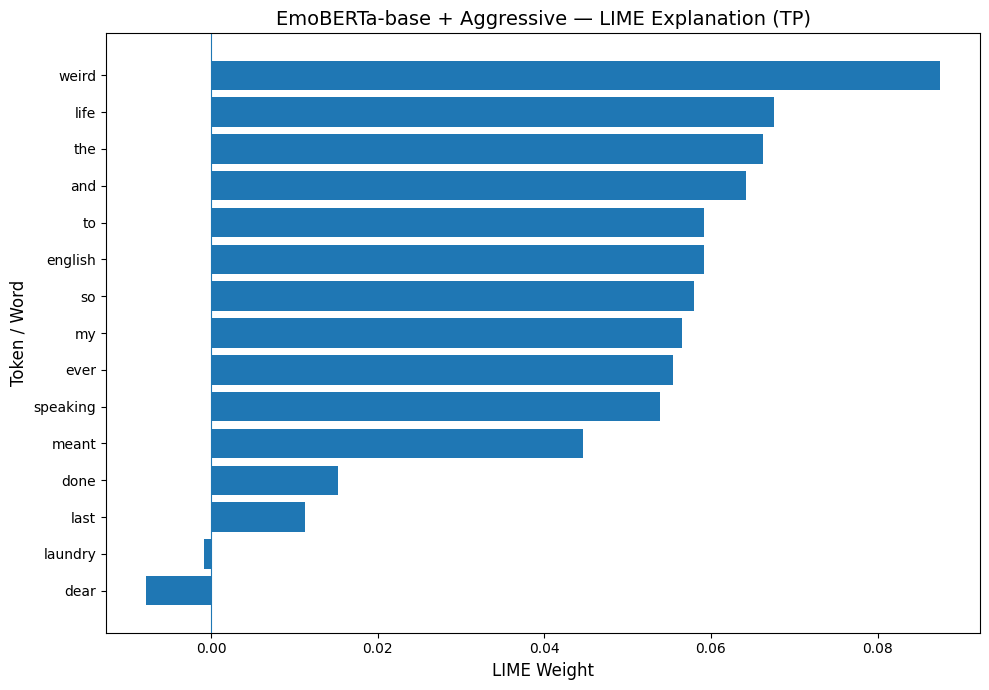

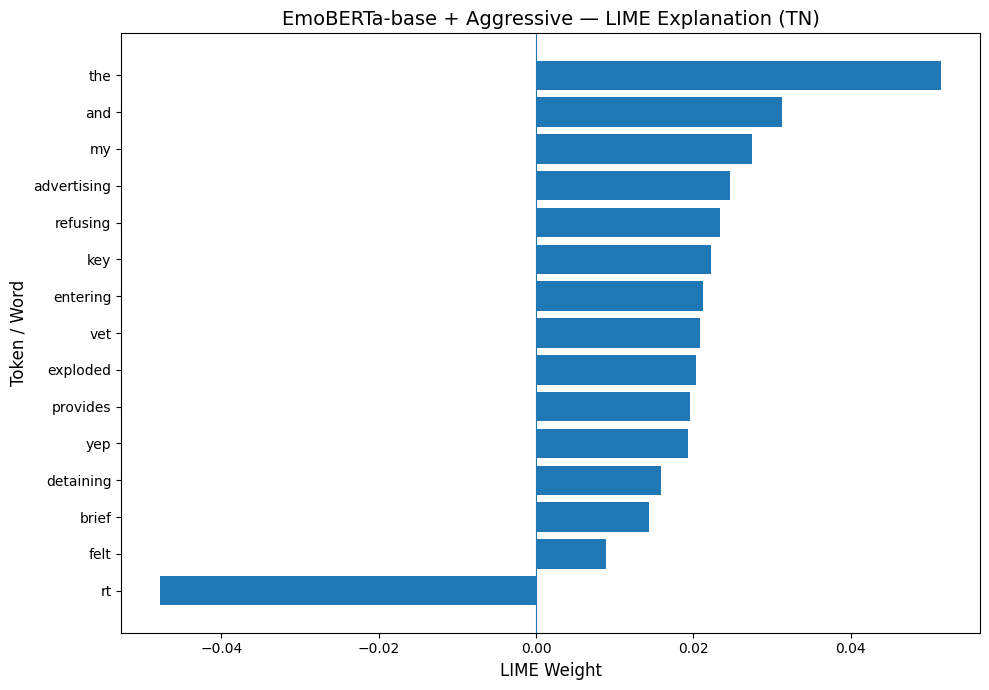

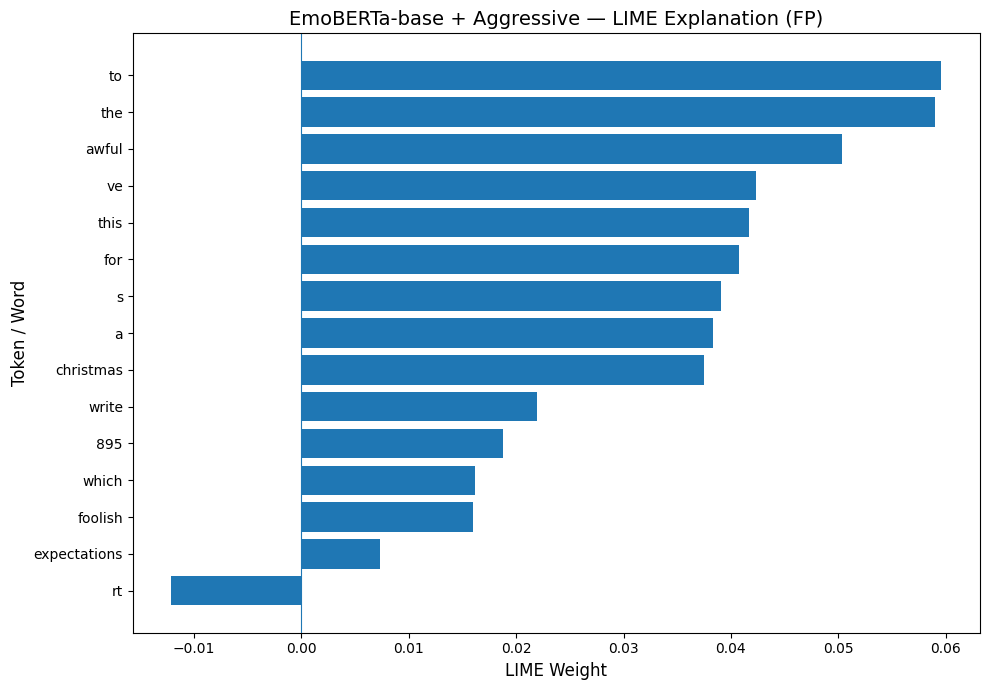

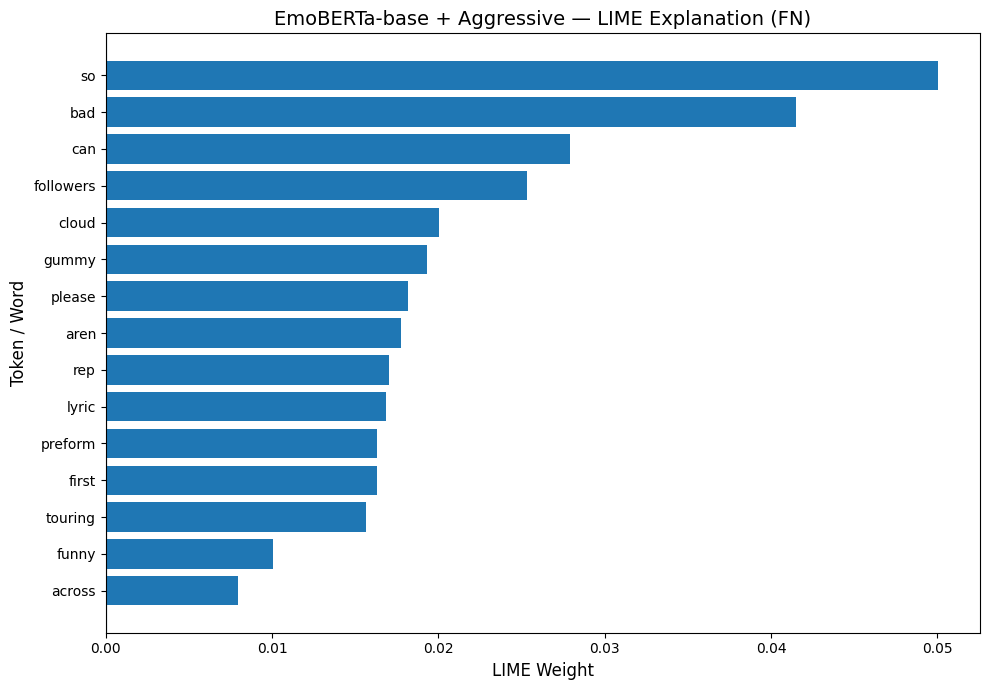


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained EmoBERTa-base model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/emoberta_aggressive/explainability/lime


In [22]:
# ============================================================

# EXPLAINABILITY — LIME

# EMOBERTA-BASE + AGGRESSIVE

# TOKEN / WORD-LEVEL LOCAL EXPLANATION

# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME ANALYSIS")
print("EMOBERTA-BASE + AGGRESSIVE")
print("=" * 70)

# ============================================================

# FIXED LIME SETTINGS

# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)

# ============================================================

# OUTPUT DIRECTORY

# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================

# MODEL

# ============================================================

model_emoberta_aggressive.eval()

print()
print("✓ EmoBERTa-base model loaded")
print("✓ Evaluation mode enabled")

# ============================================================

# BUILD TEST PREDICTIONS

# DIRECTLY FROM TEST LOADER

# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_emoberta_aggressive_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_emoberta_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            labels
            .cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

labels_np = np.array(
    labels_np
)

preds_np = np.array(
    preds_np
)

probs_np = np.array(
    probs_np
)

# ============================================================

# SELECT TP / TN / FP / FN

# FIRST MATCHING TEST EXAMPLE

# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]

if len(tp_candidates) > 0:

    selected_cases["TP"] = int(
        tp_candidates[0]
    )

if len(tn_candidates) > 0:

    selected_cases["TN"] = int(
        tn_candidates[0]
    )

if len(fp_candidates) > 0:

    selected_cases["FP"] = int(
        fp_candidates[0]
    )

if len(fn_candidates) > 0:

    selected_cases["FN"] = int(
        fn_candidates[0]
    )

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index} | "
        f"true = {labels_np[test_index]} | "
        f"pred = {preds_np[test_index]} | "
        f"probability = "
        f"{probs_np[test_index]:.4f}"
    )

# ============================================================

# GET TEST TEXT

# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_emoberta_aggressive_df.iloc[
            int(test_index)
        ]["model_text"]
    )

# ============================================================

# MAKE LIME PREDICTOR

# METADATA REMAINS FIXED FOR EACH USER

# TEXT IS PERTURBED BY LIME

# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_emoberta_aggressive_dataset[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
        .float()
    )

    def predictor(
        texts
    ):

        probability_batches = []

        # ----------------------------------------------------
        # Process perturbations in small batches
        # to avoid GPU memory overflow.
        # ----------------------------------------------------

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = emoberta_aggressive_tokenizer(
                batch_texts,
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH,
                return_attention_mask=True,
                return_tensors="pt"
            )

            lime_input_ids = (
                encoded["input_ids"]
                .to(device)
            )

            lime_attention_mask = (
                encoded["attention_mask"]
                .to(device)
            )

            batch_metadata = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )

            with torch.no_grad():

                output = model_emoberta_aggressive(
                    input_ids=lime_input_ids,
                    attention_mask=lime_attention_mask,
                    metadata=batch_metadata
                )

                probabilities = torch.softmax(
                    output["logits"],
                    dim=1
                )

            probability_batches.append(
                probabilities
                .cpu()
                .numpy()
            )

            del (
                lime_input_ids,
                lime_attention_mask,
                batch_metadata,
                output,
                probabilities
            )

            if torch.cuda.is_available():

                torch.cuda.empty_cache()

        return np.vstack(
            probability_batches
        )

    return predictor

# ============================================================

# LIME EXPLAINER

# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

# ============================================================

# RUN LIME FOR FOUR CASES

# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================

# SAVE LIME RESULTS

# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(
                    weight
                )

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "emoberta_aggressive_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)

# ============================================================

# DISPLAY + SAVE HTML

# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"emoberta_aggressive_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================

# PAPER-FRIENDLY LIME BAR PLOTS

# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"EmoBERTa-base + Aggressive — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"emoberta_aggressive_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================

# SAVE CASE INFORMATION

# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "emoberta_aggressive_lime_case_information.csv"
    ),
    index=False
)

# ============================================================

# SAVE CONFIGURATION

# ============================================================

lime_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"
}

with open(
    os.path.join(
        LIME_DIR,
        "emoberta_aggressive_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================

# COMPLETE

# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained EmoBERTa-base model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)

print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()

print(
    "LIME output directory:",
    LIME_DIR
)